In [1]:
import gc
import joblib

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import shap

from sklearn.compose import ColumnTransformer
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_squared_error, make_scorer, r2_score, root_mean_squared_error
from sklearn.model_selection import TimeSeriesSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import MultiLabelBinarizer, OneHotEncoder, StandardScaler

import xgboost as xgb
from xgboost import XGBRegressor, plot_importance
from sklearn.inspection import PartialDependenceDisplay

from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.ensemble import RandomForestRegressor

from sklearn.neural_network import MLPRegressor

<h2>Read-in Data</h2>

- wyoming + north dakota + montana data

In [2]:
campd_type_dict = {
    'State': 'string',
    'Facility Name': 'string',
    'Facility ID': 'Int32',
    'Unit ID': 'string',
    'Hour': 'Int8',
    'Operating Time': 'float32',
    'Gross Load (MW)': 'float32',
    'Steam Load (1000 lb/hr)': 'float32',
    'SO2 Mass (lbs)': 'float64',
    'SO2 Mass Measure Indicator': 'string',
    'SO2 Rate (lbs/mmBtu)': 'float32',
    'SO2 Rate Measure Indicator': 'string',
    'CO2 Mass (short tons)': 'float32',
    'CO2 Mass Measure Indicator': 'string',
    'CO2 Rate (short tons/mmBtu)': 'float32',
    'CO2 Rate Measure Indicator': 'string',
    'NOx Mass (lbs)': 'float32',
    'NOx Mass Measure Indicator': 'string',
    'NOx Rate (lbs/mmBtu)': 'float32',
    'NOx Rate Measure Indicator': 'string',
    'Heat Input (mmBtu)': 'float64',
    'Heat Input Measure Indicator': 'string',
    'Primary Fuel Type': 'string',
    'Secondary Fuel Type': 'string',
    'Unit Type': 'string',
    'SO2 Controls': 'string',
    'NOx Controls': 'string',
    'Program Code': 'string',
    'Year': 'int16',
    'Source Category': 'string',
    'Latitude': 'float32',
    'Longitude': 'float32',
    'SO2 Phase': 'string',
    'NOx Phase': 'string',
    'Operating Status': 'string',
    'Max Hourly HI Rate (mmBtu/hr)': 'float32',
    'Associated Generators & Nameplate Capacity (MWe)': 'string',
    'Nameplate Capacity (MWe)': 'float32',
    'Month': 'Int8',
    'hourly_capacity_factor': 'float32',
    'hourly_ramping_factor': 'float32',
    'Nameplate Capacity (MW) - EIA': 'float32',
    'Summer Capacity (MW)': 'float32',
    'Winter Capacity (MW)': 'float32',
    'Minimum Load (MW)': 'float32',
    'Operating Year_min': 'float32',
    'Operating Year_max': 'float32',
    'Operating Year_mean': 'float32',
    'Planned Retirement Year': 'Int16',
    'unit_age_min': 'Int8',
    'unit_age_max': 'Int8',
    'unit_age_mean': 'float32',
    'Day': 'float32',
    'Temperature (F)': 'float32'
}

In [44]:
campd_wy = pd.read_csv("WY/Hourly/Concatted File/wy_2019_2024_complete_cleaned_Full.csv", dtype=campd_type_dict)
campd_wy["Date"] = pd.to_datetime(campd_wy["Date"])
campd_wy["datetime"] = pd.to_datetime(campd_wy["datetime"])

In [ ]:
campd_nd = pd.read_csv("ND/Hourly/Concatted File/nd_2019_2024_complete_cleaned.csv", dtype=campd_type_dict)
campd_wy["Date"] = pd.to_datetime(campd_wy["Date"])
campd_wy["datetime"] = pd.to_datetime(campd_wy["datetime"])

In [ ]:
campd_mt = pd.read_csv("MT/Hourly/Concatted File/mt_2019_2024_complete_cleaned.csv", dtype=campd_type_dict)
campd_wy["Date"] = pd.to_datetime(campd_wy["Date"])
campd_wy["datetime"] = pd.to_datetime(campd_wy["datetime"])

<h2>Preprocessing Methods</h2>

In [ ]:
# manually create lag columns
def create_lag_features_per_group(group, emission_type):
    group["lag_1_hour"] = group[emission_type].shift(1)  # 1 hour lag
    group["lag_2_hours"] = group[emission_type].shift(2)  # 2 hours lag
    group["lag_1_day"] = group[emission_type].shift(24)  # 1 day lag (24 hours)
    group["lag_2_days"] = group[emission_type].shift(48)  # 2 days lag (48 hours)
    group["lag_1_week"] = group[emission_type].shift(24 * 7)  # 1 week lag (168 hours)
    group["lag_1_month"] = group[emission_type].shift(24 * 30)  # ~1 month lag (720 hours)
    group["lag_1_year"] = group[emission_type].shift(24 * 365)  # ~1 year lag (8760 hours)
    return group

def preprocess_lag_features(df, previous_year_df, emission_type):
    cutoff_year = df["Year"].min()

    # add the previous year temporarily to get lags for the first year
    df = pd.concat([df, previous_year_df])

    df = df.set_index("datetime")

    df = df.sort_index()
    df = df.sort_values(by=["Facility ID", "Unit ID", "datetime"])

    # apply the lag feature function to each group
    df = df.groupby(["Facility ID", "Unit ID"], group_keys=False).apply(
    create_lag_features_per_group, emission_type=emission_type)

    df = df.reset_index()

    # filter out the previous year again
    df = df[df["Year"] >= cutoff_year]

    # ensure to add datetime back as normal column
    df["datetime"] = pd.to_datetime({
    'year': df["Date"].dt.year,
    'month': df["Date"].dt.month,
    'day': df["Date"].dt.day,
    'hour': df["Hour"]
    })


    return df


In [ ]:
# manually one-hot encode NOx Controls
def split_outside_parentheses(s):
    parts = []
    current = []
    depth = 0  # track parentheses depth

    for char in s:
        if char == '(':
            depth += 1
        elif char == ')':
            depth = max(depth - 1, 0)
        
        # Split on ',' or '|' only if outside parentheses
        if (char == ',' or char == '|') and depth == 0:
            part = ''.join(current).strip()
            if part:
                parts.append(part)
            current = []
        else:
            current.append(char)
    
    # Append last part
    part = ''.join(current).strip()
    if part:
        parts.append(part)
    
    return parts

# function for one-hot encoding NOx Controls
def preprocess_nox_controls(df):
    df = df.copy()
    df = df.dropna(subset=['NOx Controls'])
    
    # Apply custom splitting
    control_lists = df['NOx Controls'].apply(split_outside_parentheses)
    
    # One-hot encode controls
    mlb = MultiLabelBinarizer()
    control_matrix = mlb.fit_transform(control_lists)
    
    # Create a DataFrame from the binary matrix
    controls_df = pd.DataFrame(control_matrix, columns=mlb.classes_, index=df.index)
    
    df = df.drop(columns=['NOx Controls'])
    df = pd.concat([df, controls_df], axis=1)
    
    return df, mlb.classes_  # return control column names for later use

# campd_wy, wy_control_cols = preprocess_nox_controls(campd_wy)
# wy_control_cols

In [ ]:
# manually one-hot encode Program Codes
def preprocess_program_codes(df):

    # Split the strings into lists
    program_lists = df['Program Code'].str.split(', ')

    mlb = MultiLabelBinarizer()
    program_dummies = pd.DataFrame(mlb.fit_transform(program_lists), 
                                columns=mlb.classes_, 
                                index=df.index)

    # Concatenate with original DataFrame or add to your features
    df = pd.concat([df, program_dummies], axis=1)

    return df, mlb.classes_


# campd_wy, wy_code_cols = preprocess_program_codes(campd_wy)
# wy_code_cols

<h2>Model-independent Preprocessing</h2>

- create time-lags
- manually OHE NOx controls and program codes
- (no downsampling since size is not significant for these datasets)
- remove rows where NOx rate was not fully measured (NOx mass is based on rate measurements)

<h3>WY</h3>

In [ ]:
# read in previous year to get according lags
campd_wy_2018 = pd.read_csv("WY/Hourly/Before 2019/emissions-hourly-2018-wy.csv", dtype=campd_type_dict, date_format=["Date"])
campd_wy_2018 = campd_wy_2018[["Facility ID", "Unit ID", "Date", "Hour", "NOx Mass (lbs)"]]
campd_wy_2018["datetime"] = pd.to_datetime({
    'year': campd_wy_2018["Date"].dt.year,
    'month': campd_wy_2018["Date"].dt.month,
    'day': campd_wy_2018["Date"].dt.day,
    'hour': campd_wy_2018["Hour"]
    })
campd_wy_2018["NOx Mass (lbs)"] = campd_wy_2018["NOx Mass (lbs)"].fillna(0)

# compute lags
campd_df = preprocess_lag_features(campd_wy, campd_wy_2018, "NOx Mass (lbs)")

In [ ]:
campd_df.to_csv("WY/Hourly/Concatted File/Modeling/XGB/NOx/wy_2019_2024_complete_cleaned_Full_with_NOx_lags.csv", index=False)

In [ ]:
campd_df = pd.read_csv("WY/Hourly/Concatted File/Modeling/XGB/NOx/wy_2019_2024_complete_cleaned_Full_with_NOx_lags.csv", dtype=campd_type_dict)
campd_df["Date"] = pd.to_datetime(campd_df["Date"])
campd_df["datetime"] = pd.to_datetime(campd_df["datetime"])

In [ ]:
# manually one-hot encode nox controls and program codes
campd_df, df_control_cols = preprocess_nox_controls(campd_df)
campd_df, df_code_cols = preprocess_program_codes(campd_df)

# manually sin/cos encode cyclical features hour, day, month
def encode_cyclical(df, col, max_val):
    df[f"{col}_sin"] = np.sin(2 * np.pi * df[col] / max_val)
    df[f"{col}_cos"] = np.cos(2 * np.pi * df[col] / max_val)
    col_names = [f"{col}_sin", f"{col}_cos"]
    return df, col_names
campd_df, hour_cols = encode_cyclical(campd_df, "Hour", 24) # Daily seasonality
campd_df, day_cols = encode_cyclical(campd_df, "Day", 7)  # Weekly seasonality
campd_df, month_cols = encode_cyclical(campd_df, "Month", 12) # Yearly seasonality
cyclical_cols = hour_cols + day_cols + month_cols

In [ ]:
# NOx is mass is based on rate measurements here -> we filter for rate measurements
campd_df["NOx Mass Measure Indicator"].value_counts()

NOx Mass Measure Indicator
Calculated    1925653
Nothing        617044
Name: count, dtype: Int64

In [7]:
campd_df["NOx Rate Measure Indicator"].value_counts()

NOx Rate Measure Indicator
Measured      1901888
Nothing        617044
Substitute      23765
Name: count, dtype: Int64

In [8]:
campd_df.shape

(2542697, 79)

In [ ]:
campd_df = campd_df[campd_df["NOx Rate Measure Indicator"] != "Substitute"] # remove the 23765 rows where a substitute calculation was used for NOx Rate
campd_df.shape

(2518932, 79)

In [10]:
campd_df.to_csv("WY/Hourly/Concatted File/Modeling/XGB/NOx/wy_2019_2024_complete_cleaned_Full_manually_encoded.gz", index=False, compression="gzip")

In [3]:
campd_df = pd.read_csv("WY/Hourly/Concatted File/Modeling/XGB/NOx/wy_2019_2024_complete_cleaned_Full_manually_encoded.gz", dtype=campd_type_dict)

In [25]:
campd_df.shape

(2518932, 79)

In [34]:
campd_df["Program Code"].unique()

<StringArray>
['ARP, MATS', 'ARP']
Length: 2, dtype: string

<h3>ND</h3>

In [ ]:
# read in previous year to get according lags
campd_nd_2018 = pd.read_csv("ND/Hourly/Before 2019/emissions-hourly-2018-nd.csv", dtype=campd_type_dict, date_format=["Date"])
campd_nd_2018 = campd_nd_2018[["Facility ID", "Unit ID", "Date", "Hour", "NOx Mass (lbs)"]]
campd_nd_2018["datetime"] = pd.to_datetime({
    'year': campd_nd_2018["Date"].dt.year,
    'month': campd_nd_2018["Date"].dt.month,
    'day': campd_nd_2018["Date"].dt.day,
    'hour': campd_nd_2018["Hour"]
    })
campd_nd_2018["NOx Mass (lbs)"] = campd_nd_2018["NOx Mass (lbs)"].fillna(0)

# compute lags
campd_nd = preprocess_lag_features(campd_nd, campd_nd_2018, "NOx Mass (lbs)")

campd_nd.to_csv("ND/Hourly/Concatted File/Modeling/XGB/NOx/nd_2019_2024_complete_cleaned_Full_with_NOx_lags.csv", index=False)

campd_nd["Date"] = pd.to_datetime(campd_nd["Date"])
campd_nd["datetime"] = pd.to_datetime(campd_nd["datetime"])

# manually one-hot encode nox controls and program codes
campd_nd, nd_control_cols = preprocess_nox_controls(campd_nd)
campd_nd, nd_code_cols = preprocess_program_codes(campd_nd)

# manually sin/cos encode cyclical features hour, day, month
def encode_cyclical(df, col, max_val):
    df[f"{col}_sin"] = np.sin(2 * np.pi * df[col] / max_val)
    df[f"{col}_cos"] = np.cos(2 * np.pi * df[col] / max_val)
    col_names = [f"{col}_sin", f"{col}_cos"]
    return df, col_names
campd_nd, hour_cols = encode_cyclical(campd_nd, "Hour", 24) # Daily seasonality
campd_nd, day_cols = encode_cyclical(campd_nd, "Day", 7)  # Weekly seasonality
campd_nd, month_cols = encode_cyclical(campd_nd, "Month", 12) # Yearly seasonality
cyclical_cols = hour_cols + day_cols + month_cols

# mass is calculated like in WY -> we remove substitute calculations of NOx Rate
campd_nd = campd_nd[campd_nd["NOx Rate Measure Indicator"] != "Substitute"] 

campd_nd.to_csv("WY/Hourly/Concatted File/Modeling/XGB/NOx/nd_2019_2024_complete_cleaned_Full_manually_encoded.csv", index=False)

In [ ]:
campd_nd.to_csv("WY/Hourly/Concatted File/Modeling/XGB/NOx/nd_2019_2024_complete_cleaned_Full_manually_encoded.csv", index=False)

In [ ]:
campd_nd = pd.read_csv("WY/Hourly/Concatted File/Modeling/XGB/NOx/nd_2019_2024_complete_cleaned_Full_manually_encoded.csv", dtype=campd_type_dict)

In [24]:
campd_nd.shape

(1059391, 79)

In [ ]:
campd_nd["Program Code"].unique()

<StringArray>
['ARP, NSPS4T', 'ARP, MATS', 'ARP']
Length: 3, dtype: string

<h3>MT</h3>

In [ ]:
# read in previous year to get according lags
campd_mt_2018 = pd.read_csv("MT/Hourly/Before 2019/emissions-hourly-2018-mt.csv", dtype=campd_type_dict, date_format=["Date"])
campd_mt_2018 = campd_mt_2018[["Facility ID", "Unit ID", "Date", "Hour", "NOx Mass (lbs)"]]
campd_mt_2018["datetime"] = pd.to_datetime({
    'year': campd_mt_2018["Date"].dt.year,
    'month': campd_mt_2018["Date"].dt.month,
    'day': campd_mt_2018["Date"].dt.day,
    'hour': campd_mt_2018["Hour"]
    })
campd_mt_2018["NOx Mass (lbs)"] = campd_mt_2018["NOx Mass (lbs)"].fillna(0)

# compute lags
campd_mt = preprocess_lag_features(campd_mt, campd_mt_2018, "NOx Mass (lbs)")

campd_mt.to_csv("MT/Hourly/Concatted File/Modeling/XGB/NOx/mt_2019_2024_complete_cleaned_Full_with_NOx_lags.csv", index=False)

campd_mt["Date"] = pd.to_datetime(campd_mt["Date"])
campd_mt["datetime"] = pd.to_datetime(campd_mt["datetime"])

# manually one-hot encode nox controls and program codes
campd_mt, mt_control_cols = preprocess_nox_controls(campd_mt)
campd_mt, mt_code_cols = preprocess_program_codes(campd_mt)

# manually sin/cos encode cyclical features hour, day, month
def encode_cyclical(df, col, max_val):
    df[f"{col}_sin"] = np.sin(2 * np.pi * df[col] / max_val)
    df[f"{col}_cos"] = np.cos(2 * np.pi * df[col] / max_val)
    col_names = [f"{col}_sin", f"{col}_cos"]
    return df, col_names
campd_mt, hour_cols = encode_cyclical(campd_mt, "Hour", 24) # Daily seasonality
campd_mt, day_cols = encode_cyclical(campd_mt, "Day", 7)  # Weekly seasonality
campd_mt, month_cols = encode_cyclical(campd_mt, "Month", 12) # Yearly seasonality
cyclical_cols = hour_cols + day_cols + month_cols

# mass is calculated like in WY -> we remove substitute calculations of NOx Rate
campd_mt = campd_mt[~campd_mt["NOx Rate Measure Indicator"].isin(["Calculated", "Substitute", "Measured and Substitute"])]

campd_mt.to_csv("WY/Hourly/Concatted File/Modeling/XGB/NOx/mt_2019_2024_complete_cleaned_Full_manually_encoded.csv", index=False)

In [ ]:
campd_mt = pd.read_csv("WY/Hourly/Concatted File/Modeling/XGB/NOx/mt_2019_2024_complete_cleaned_Full_manually_encoded.csv", dtype=campd_type_dict)

In [33]:
campd_mt.shape

(1428787, 76)

In [ ]:
campd_mt["Program Code"].unique()

<StringArray>
['ARP', 'ARP, MATS']
Length: 2, dtype: string

<h2>Regression Models</h2>

<h3>Random Forest</h3>

<h4>Preprocessing</h4>

In [ ]:
# default params are:
# n_estimators=100, *, criterion='gini', max_depth=None, min_samples_split=2, 
# min_samples_leaf=1, min_weight_fraction_leaf=0.0, max_features='sqrt', 
# max_leaf_nodes=None, min_impurity_decrease=0.0, bootstrap=True, oob_score=False,
#  n_jobs=None, random_state=None, verbose=0, warm_start=False, class_weight=None, 
# ccp_alpha=0.0, max_samples=None, monotonic_cst=None

In [ ]:
campd_df = pd.read_csv("WY/Hourly/Concatted File/Modeling/XGB/NOx/wy_2019_2024_complete_cleaned_Full_manually_encoded.gz", dtype=campd_type_dict)

In [ ]:
df_control_cols = ['Dry Low NOx Burners', 'Low NOx Burner Technology (Dry Bottom only)',
       'Low NOx Burner Technology w/ Closed-coupled OFA',
       'Low NOx Burner Technology w/ Overfire Air',
       'Low NOx Burner Technology w/ Separated OFA', 'Nothing', 'Overfire Air',
       'Selective Catalytic Reduction',
       'Selective Catalytic Reduction (Began Jun 27, 2019)',
       'Selective Non-catalytic Reduction']
df_code_cols = ['ARP', 'MATS']
cyclical_cols = ['Hour_sin', 'Hour_cos', 'Day_sin',
       'Day_cos', 'Month_sin', 'Month_cos']
lag_cols = [
    "lag_1_hour",
    "lag_2_hours",
    "lag_1_day",
    "lag_2_days",
    "lag_1_week",
    "lag_1_month",
    "lag_1_year"
       ]

# features
num_features = ['Gross Load (MW)', 
                'Heat Input (mmBtu)',
                'Latitude', 'Longitude',
                'Nameplate Capacity (MWe)', 'hourly_capacity_factor',
                'hourly_ramping_factor',
                'Summer Capacity (MW)',
                'Winter Capacity (MW)', 
                'Minimum Load (MW)', 
                 'Year',
                 'Temperature (F)'
                 ] + lag_cols

unencoded_cat_features = ['Month', 'Hour', 'Day', 
                    'Source Category', 
                    'NOx Phase', 'Unit Type', 'Primary Fuel Type', 
                    'Secondary Fuel Type'] 

encoded_cat_features = list(df_control_cols) + list(df_code_cols) # for passthrough of the manually one-hot encoded cols

target_variable = "NOx Mass (lbs)"

# sort to put it in appropriate time series format
campd_df = campd_df.sort_values(by=["datetime","Facility ID", "Unit ID"])

# split manually by year 2024
X_train = campd_df[(campd_df["Year"] < 2024) & (campd_df["NOx Mass (lbs)"].notna())][num_features + unencoded_cat_features + encoded_cat_features]
y_train = campd_df[(campd_df["Year"] < 2024) & (campd_df["NOx Mass (lbs)"].notna())][target_variable]  
X_test = campd_df[(campd_df["Year"] == 2024) & (campd_df["NOx Mass (lbs)"].notna())][num_features + unencoded_cat_features + encoded_cat_features]
y_test = campd_df[(campd_df["Year"] ==  2024) & (campd_df["NOx Mass (lbs)"].notna())][target_variable]

preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), unencoded_cat_features), 
        ('num', 'passthrough', num_features),
        ('encoded', 'passthrough', encoded_cat_features) 
    ]
)

preprocessor.set_output(transform='pandas') # transform pandas.NA values to normal nan

X_train = preprocessor.fit_transform(X_train)
X_test = preprocessor.transform(X_test)

<h4>No Lags</h4>

In [ ]:
# took approx. 11 mins to compute (full train data), model size is >11gb

rf_model_no_lags_full_train = RandomForestRegressor(random_state=42, n_jobs=-1)

# Train Random Forest model with default parameters
rf_model_no_lags_full_train.fit(X_train, y_train.values.ravel())

RandomForestRegressor(n_jobs=-1, random_state=42)

R^2 Score: 0.8845
Mean Squared Error (MSE): 5361.0393
Root Mean Squared Error (RMSE): 73.2191
Normalized RMSE (by std): 0.3400


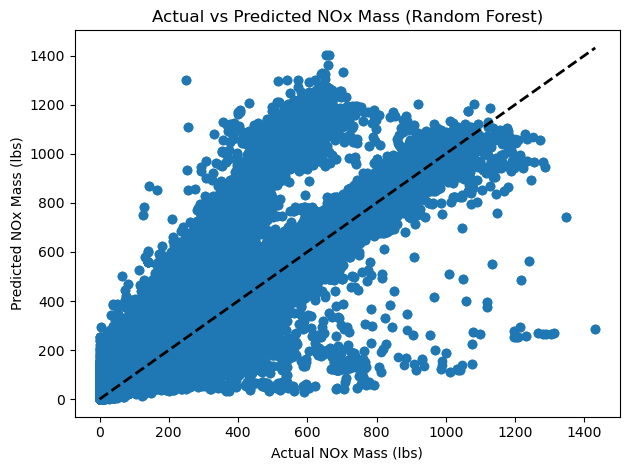

In [ ]:
# default model (no lags, no unmeasured data, with temps)

# rf model trained on full training data
# only very small improvement over downsampled training data (see below)

y_pred = rf_model_no_lags_full_train.predict(X_test)

# Set all predictions below 0 to 0
y_pred[y_pred < 0] = 0

print(f"R^2 Score: {r2_score(y_test, y_pred):.4f}")
print(f"Mean Squared Error (MSE): {mean_squared_error(y_test, y_pred):.4f}")
print(f"Root Mean Squared Error (RMSE): {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}")
print(f"Normalized RMSE (by std): {np.sqrt(mean_squared_error(y_test, y_pred)) / np.std(y_test):.4f}")

plt.scatter(y_test, y_pred)
plt.xlabel("Actual NOx Mass (lbs)")
plt.ylabel("Predicted NOx Mass (lbs)")
plt.title("Actual vs Predicted NOx Mass (Random Forest)")
plt.plot([min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], 'k--', lw=2)
plt.tight_layout()
plt.show()

In [ ]:
print(len(rf_model_no_lags_full_train.estimators_))  # Number of trees

100


In [ ]:
# per default, sklearn sets no max_depth for rf trees so we look at efective depth

tree_depths = [estimator.tree_.max_depth for estimator in rf_model_no_lags_full_train.estimators_]
print("Effective max depth:", max(tree_depths))
print("Average depth:", sum(tree_depths) / len(tree_depths))
print("Depths of first 5 trees:", tree_depths[:5])

# deep trees

Effective max depth: 94
Average depth: 82.01
Depths of first 5 trees: [81, 80, 80, 89, 78]


In [ ]:
# downsample the training data to 50%
# Sample while keeping the original time order (just doing .sample() shuffles order)
sample_indices = X_train.sample(frac=0.5, random_state=42).index
X_sampled = X_train.loc[X_train.index.isin(sample_indices)]
y_sampled = y_train.loc[y_train.index.isin(sample_indices)]
X_sampled.shape

(1053450, 106)

In [ ]:
# still takes approx. 5 mins to compute (50% sample)

rf_model_no_lags = RandomForestRegressor(random_state=42, n_jobs=-1)

# Train Random Forest model with default parameters
rf_model_no_lags.fit(X_sampled, y_sampled.values.ravel())

RandomForestRegressor(n_jobs=-1, random_state=42)

In [ ]:
joblib.dump(rf_model_no_lags, "WY/Hourly/Concatted File/Modeling/RF/NOx/Trained Models/rf_default_model_wy_no_lags_with_unmeasured_with_temps.json", compress=True)

['WY/Hourly/Concatted File/Modeling/RF/NOx/Trained Models/rf_default_model_wy_no_lags_with_unmeasured_with_temps.json']

In [9]:
rf_model_no_lags = joblib.load("WY/Hourly/Concatted File/Modeling/RF/NOx/Trained Models/rf_default_model_wy_no_lags_with_unmeasured_with_temps.json")

R^2 Score: 0.8840
Mean Squared Error (MSE): 5382.8188
Root Mean Squared Error (RMSE): 73.3677
Normalized RMSE (by std): 0.3407


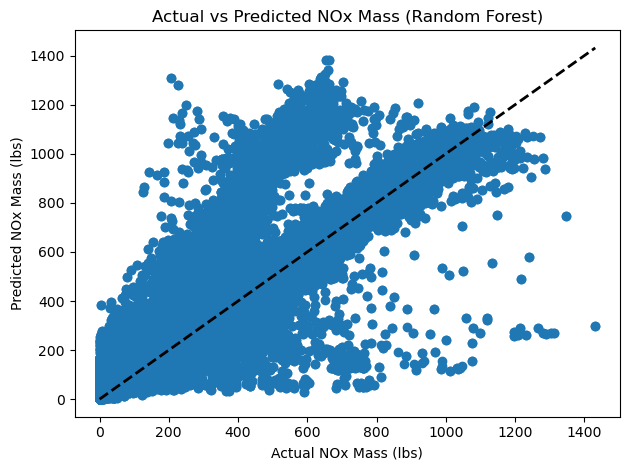

In [ ]:
# default model (no lags, no unmeasured data, with temps)

# rf model trained on 50% sampled train data

y_pred = rf_model_no_lags.predict(X_test)

# Set all predictions below 0 to 0
y_pred[y_pred < 0] = 0

print(f"R^2 Score: {r2_score(y_test, y_pred):.4f}")
print(f"Mean Squared Error (MSE): {mean_squared_error(y_test, y_pred):.4f}")
print(f"Root Mean Squared Error (RMSE): {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}")
print(f"Normalized RMSE (by std): {np.sqrt(mean_squared_error(y_test, y_pred)) / np.std(y_test):.4f}")

plt.scatter(y_test, y_pred)
plt.xlabel("Actual NOx Mass (lbs)")
plt.ylabel("Predicted NOx Mass (lbs)")
plt.title("Actual vs Predicted NOx Mass (Random Forest)")
plt.plot([min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], 'k--', lw=2)
plt.tight_layout()
plt.show()

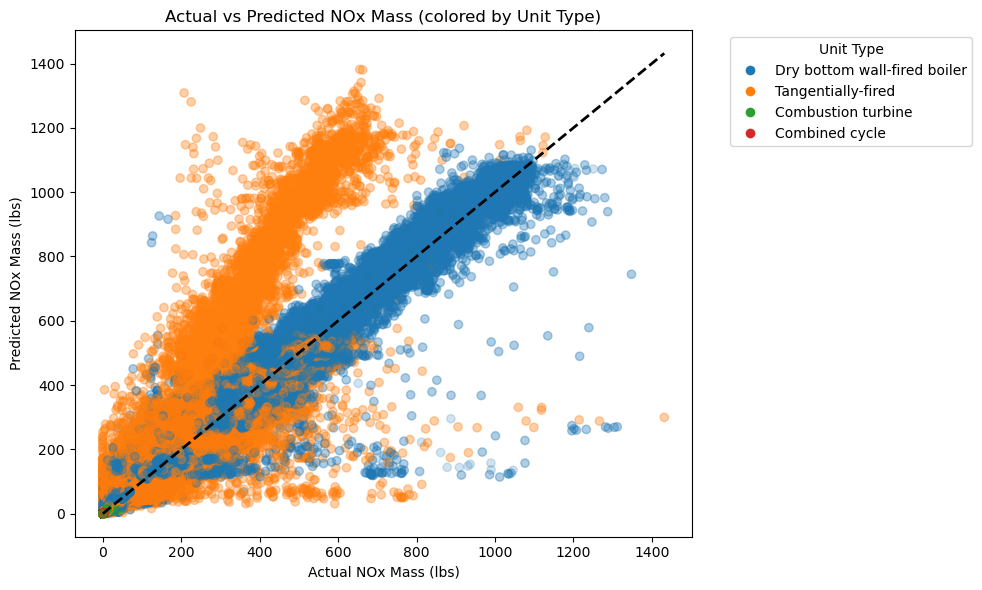

In [124]:
train_mask = (campd_df["Year"] < 2024) & (campd_df["NOx Mass (lbs)"].notna())
test_mask = (campd_df["Year"] == 2024) & (campd_df["NOx Mass (lbs)"].notna())

unit_types_test = campd_df.loc[test_mask, "Unit Type"].reset_index(drop=True)

y_test = pd.Series(y_test).reset_index(drop=True)
y_pred = pd.Series(y_pred).reset_index(drop=True)

unique_unit_types = unit_types_test.unique()
palette = sns.color_palette("tab10", len(unique_unit_types))  
color_mapping = dict(zip(unique_unit_types, palette))
colors = unit_types_test.map(color_mapping)

plt.figure(figsize=(10, 6))
scatter = plt.scatter(y_test, y_pred, c=colors, alpha=0.2)
plt.xlabel("Actual NOx Mass (lbs)")
plt.ylabel("Predicted NOx Mass (lbs)")
plt.title("Actual vs Predicted NOx Mass (colored by Unit Type)")
plt.plot(
    [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())],
    [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())],
    'k--', lw=2
)

handles = [plt.Line2D([0], [0], marker='o', color='w', label=ut,
                      markerfacecolor=color_mapping[ut], markersize=8)
           for ut in unique_unit_types]
plt.legend(handles=handles, title="Unit Type", bbox_to_anchor=(1.05, 1), loc='upper left')

plt.tight_layout()
plt.show()




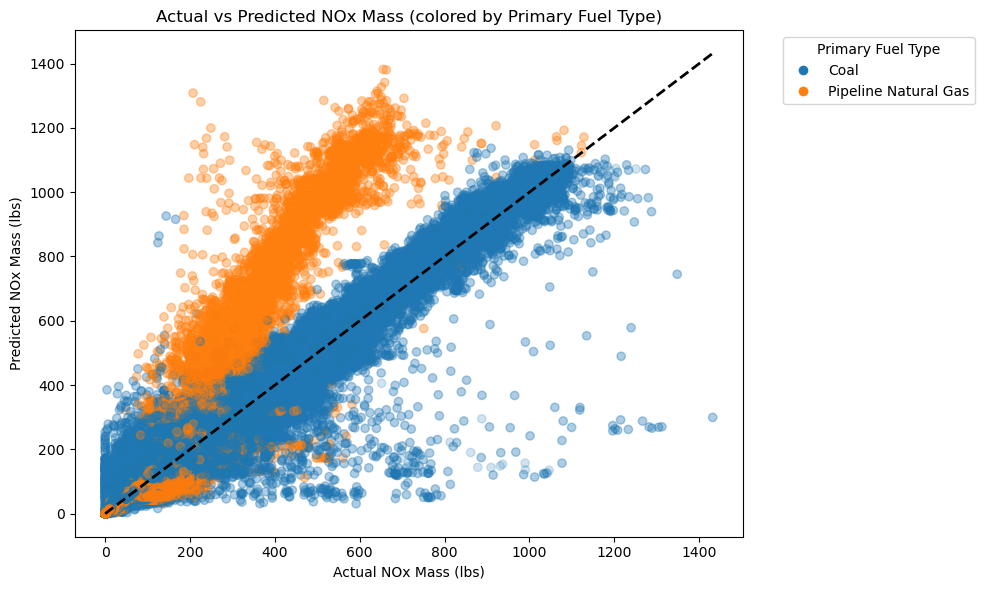

In [ ]:
train_mask = (campd_df["Year"] < 2024) & (campd_df["NOx Mass (lbs)"].notna())
test_mask = (campd_df["Year"] == 2024) & (campd_df["NOx Mass (lbs)"].notna())

fuel_types_test = campd_df.loc[test_mask, "Primary Fuel Type"].reset_index(drop=True)

y_test = pd.Series(y_test).reset_index(drop=True)
y_pred = pd.Series(y_pred).reset_index(drop=True)

unique_fuel_types = fuel_types_test.unique()
palette = sns.color_palette("tab10", len(unique_fuel_types))  
color_mapping = dict(zip(unique_fuel_types, palette))
colors = fuel_types_test.map(color_mapping)

plt.figure(figsize=(10, 6))
scatter = plt.scatter(y_test, y_pred, c=colors, alpha=0.2)
plt.xlabel("Actual NOx Mass (lbs)")
plt.ylabel("Predicted NOx Mass (lbs)")
plt.title("Actual vs Predicted NOx Mass (colored by Primary Fuel Type)")
plt.plot(
    [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())],
    [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())],
    'k--', lw=2
)

handles = [plt.Line2D([0], [0], marker='o', color='w', label=ut,
                      markerfacecolor=color_mapping[ut], markersize=8)
           for ut in unique_fuel_types]
plt.legend(handles=handles, title="Primary Fuel Type", bbox_to_anchor=(1.05, 1), loc='upper left')

plt.tight_layout()
plt.show()

<h3>XGBoost</h3>

<h5>Preprocessing</h5>

In [ ]:
campd_df = pd.read_csv("WY/Hourly/Concatted File/Modeling/XGB/NOx/wy_2019_2024_complete_cleaned_Full_manually_encoded.gz", dtype=campd_type_dict)

In [49]:
df_control_cols = ['Dry Low NOx Burners', 'Low NOx Burner Technology (Dry Bottom only)',
       'Low NOx Burner Technology w/ Closed-coupled OFA',
       'Low NOx Burner Technology w/ Overfire Air',
       'Low NOx Burner Technology w/ Separated OFA', 'Nothing', 'Overfire Air',
       'Selective Catalytic Reduction',
       'Selective Catalytic Reduction (Began Jun 27, 2019)',
       'Selective Non-catalytic Reduction']
df_code_cols = ['ARP', 'MATS']
cyclical_cols = ['Hour_sin', 'Hour_cos', 'Day_sin',
       'Day_cos', 'Month_sin', 'Month_cos']
lag_cols = [
    "lag_1_hour",
    "lag_2_hours",
    "lag_1_day",
    "lag_2_days",
    "lag_1_week",
    "lag_1_month",
    "lag_1_year"
       ]

In [50]:
# features
num_features = ['Gross Load (MW)', 
                    'Heat Input (mmBtu)',
                'Latitude', 'Longitude',
                'Nameplate Capacity (MWe)', 'hourly_capacity_factor',
                'hourly_ramping_factor',
                'Summer Capacity (MW)',
                'Winter Capacity (MW)', 
                'Minimum Load (MW)', 
                 'Year',
                 'Temperature (F)'
                 ] + lag_cols

unencoded_cat_features = ['Month', 'Hour', 'Day', 
                    'Source Category', 
                    'NOx Phase', 'Unit Type', 'Primary Fuel Type', 
                    'Secondary Fuel Type'] 

encoded_cat_features = list(df_control_cols) + list(df_code_cols) # for passthrough of the manually one-hot encoded cols

target_variable = "NOx Mass (lbs)"

# sort to put it in appropriate time series format
campd_df = campd_df.sort_values(by=["datetime","Facility ID", "Unit ID"])

# split manually by year 2024
X_train = campd_df[(campd_df["Year"] < 2024) & (campd_df["NOx Mass (lbs)"].notna())][num_features + unencoded_cat_features + encoded_cat_features]
y_train = campd_df[(campd_df["Year"] < 2024) & (campd_df["NOx Mass (lbs)"].notna())][target_variable]  
X_test = campd_df[(campd_df["Year"] == 2024) & (campd_df["NOx Mass (lbs)"].notna())][num_features + unencoded_cat_features + encoded_cat_features]
y_test = campd_df[(campd_df["Year"] ==  2024) & (campd_df["NOx Mass (lbs)"].notna())][target_variable]

preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), unencoded_cat_features), 
        ('num', 'passthrough', num_features),
        ('encoded', 'passthrough', encoded_cat_features)  # add the pre-encoded features (NOx Controls)
    ]
)

preprocessor.set_output(transform='pandas') # transform pandas.NA values to normal nan


ColumnTransformer(transformers=[('cat',
                                 OneHotEncoder(handle_unknown='ignore',
                                               sparse_output=False),
                                 ['Month', 'Hour', 'Day', 'Source Category',
                                  'NOx Phase', 'Unit Type', 'Primary Fuel Type',
                                  'Secondary Fuel Type']),
                                ('num', 'passthrough',
                                 ['Gross Load (MW)', 'Heat Input (mmBtu)',
                                  'Latitude', 'Longitude',
                                  'Nameplate Capacity (MWe)',
                                  'hourly_capacity_factor',
                                  'hourly_ramping_facto...
                                ('encoded', 'passthrough',
                                 ['Dry Low NOx Burners',
                                  'Low NOx Burner Technology (Dry Bottom only)',
                                  'Low NOx Burner Technology w/ Closed-coupled '
                                  'OFA',
                                  'Low NOx Burner Technology w/ Overfire Air',
                                  'Low NOx Burner Technology w/ Separated OFA',
                                  'Nothing', 'Overfire Air',
                                  'Selective Catalytic Reduction',
                                  'Selective Catalytic Reduction (Began Jun '
                                  '27, 2019)',
                                  'Selective Non-catalytic Reduction', 'ARP',
                                  'MATS'])])

In [ ]:
X_train.to_csv("WY/Hourly/Concatted File/Modeling/XGB/NOx/X_train.csv", index=False)
X_test.to_csv("WY/Hourly/Concatted File/Modeling/XGB/NOx/X_test.csv", index=False)
y_train.to_csv("WY/Hourly/Concatted File/Modeling/XGB/NOx/y_train.csv", index=False)
y_test.to_csv("WY/Hourly/Concatted File/Modeling/XGB/NOx/y_test.csv", index=False)

In [ ]:
X_train = pd.read_csv("WY/Hourly/Concatted File/Modeling/XGB/NOx/X_train.csv", dtype=campd_type_dict)
X_test = pd.read_csv("WY/Hourly/Concatted File/Modeling/XGB/NOx/X_test.csv", dtype=campd_type_dict)

In [ ]:
y_train = pd.read_csv("WY/Hourly/Concatted File/Modeling/XGB/NOx/y_train.csv")
y_test = pd.read_csv("WY/Hourly/Concatted File/Modeling/XGB/NOx/y_test.csv")

In [51]:
X_train = preprocessor.fit_transform(X_train)
X_test = preprocessor.transform(X_test)

In [ ]:
X_train.to_csv("WY/Hourly/Concatted File/Modeling/XGB/NOx/X_train_processed.csv", index=False)
X_test.to_csv("WY/Hourly/Concatted File/Modeling/XGB/NOx/X_test_processed.csv", index=False)

In [ ]:
X_train = pd.read_csv("WY/Hourly/Concatted File/Modeling/XGB/NOx/X_train_processed.csv", dtype=campd_type_dict)
X_test = pd.read_csv("WY/Hourly/Concatted File/Modeling/XGB/NOx/X_test_processed.csv", dtype=campd_type_dict)

In [7]:
dtrain = xgb.DMatrix(X_train, label=y_train)
dtest = xgb.DMatrix(X_test, label=y_test)

In [20]:
dtrain.save_binary("WY/Hourly/Concatted File/Modeling/XGB/NOx/dtrain_wy_full_2019_2023.buffer")
dtest.save_binary("WY/Hourly/Concatted File/Modeling/XGB/NOx/dtest_wy_full_2024.buffer")

In [130]:
dtrain = xgb.DMatrix("WY/Hourly/Concatted File/Modeling/XGB/NOx/dtrain_wy_full_2019_2023.buffer")
dtest = xgb.DMatrix("WY/Hourly/Concatted File/Modeling/XGB/NOx/dtest_wy_full_2024.buffer")

In [ ]:
# default parameters for comparison
default_params = {
    # "n_estimators": 100, # number of trees (larger value, more likely to overfit)
    # "max_depth":  6, # max depth of a tree (larger value, more complex, more likely to overfit)
    # "learning_rate": 0.5, # step size shrinkage eta (lower value, more conservative)
    # "subsample": 1, # random subset size of data to use for each tree (lower value, more conservative)
    # "colsample_bytree": 1, # random subset of features to consider for each tree (lower value, more conservative)
    # "gamma": 0, # min loss reduction to make a split (larger value, more conservative)
    # "reg_alpha": 0, # L1 regularization on weights (larger value, more conservative)
    # "reg_lambda": 1, # L2 regularization on weights (larger value, more conservative)
    # "min_child_weight": 1, # min sum of instance weight (hessian) needed in a child (larger value, more conservative)
    # "tree_method": "auto" # automatically chooses exact or approximation method based on data size

    # needed params for xgb.train
    "objective": "reg:squarederror",
    'eval_metric': 'rmse',
}

<h5>Train All, Test Year 2024</h5>

R^2 Score: 0.9043
Mean Squared Error (MSE): 4439.2427
Root Mean Squared Error (RMSE): 66.6276
Normalized RMSE (by std): 0.3093


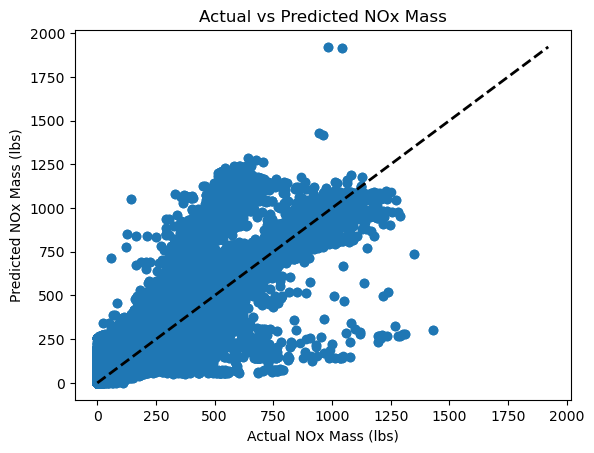

In [ ]:
# model with default parameters (no lags, no unmeasured data, with temps)

xgb_default_model = xgb.train(params=default_params, dtrain=dtrain, num_boost_round=100)

# dump model
xgb_default_model.save_model("WY/Hourly/Concatted File/Modeling/XGB/NOx/Trained Models/xgb_default_model_wy_no_lags_with_unmeasured_with_temps.json")

y_pred = xgb_default_model.predict(dtest)

# set all predictions below 0 to 0
y_pred[y_pred < 0] = 0

y_test = dtest.get_label() # get y_test from dmatrix

print(f"R^2 Score: {r2_score(y_test, y_pred):.4f}")
print(f"Mean Squared Error (MSE): {mean_squared_error(y_test, y_pred):.4f}")
print(f"Root Mean Squared Error (RMSE): {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}")
print(f"Normalized RMSE (by std): {np.sqrt(mean_squared_error(y_test, y_pred)) / np.std(y_test):.4f}")

plt.scatter(y_test, y_pred)
plt.xlabel("Actual NOx Mass (lbs)")
plt.ylabel("Predicted NOx Mass (lbs)")
plt.title("Actual vs Predicted NOx Mass")
plt.plot([min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], 'k--', lw=2)
plt.show()

R^2 Score: 0.9858
Mean Squared Error (MSE): 659.2536
Root Mean Squared Error (RMSE): 25.6759
Normalized RMSE (by std): 0.1192


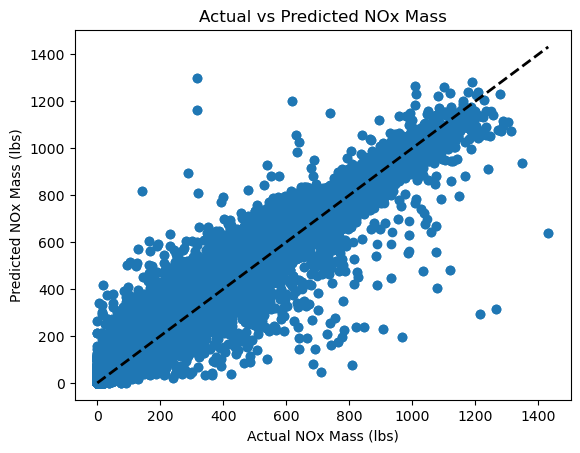

In [131]:
# model with default parameters (with lags, no unmeasured data, with temps)

xgb_default_model = xgb.train(params=default_params, dtrain=dtrain, num_boost_round=100)

# dump model
xgb_default_model.save_model("WY/Hourly/Concatted File/Modeling/XGB/NOx/Trained Models/xgb_default_model_wy_with_lags_with_unmeasured_with_temps.json")

y_pred = xgb_default_model.predict(dtest)

# set all predictions below 0 to 0
y_pred[y_pred < 0] = 0

y_test = dtest.get_label() # get y_test from dmatrix

print(f"R^2 Score: {r2_score(y_test, y_pred):.4f}")
print(f"Mean Squared Error (MSE): {mean_squared_error(y_test, y_pred):.4f}")
print(f"Root Mean Squared Error (RMSE): {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}")
print(f"Normalized RMSE (by std): {np.sqrt(mean_squared_error(y_test, y_pred)) / np.std(y_test):.4f}")

plt.scatter(y_test, y_pred)
plt.xlabel("Actual NOx Mass (lbs)")
plt.ylabel("Predicted NOx Mass (lbs)")
plt.title("Actual vs Predicted NOx Mass")
plt.plot([min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], 'k--', lw=2)
plt.show()

<h5>Transferability Tests</h5>

- in 1. and 2., we use supplementary training data to evaluate the performance impact on the wy model
- in 3. we use the original wy model (2019-2023) to predict nd and mt data (2024)

<h6>1. Train: WY + NY/TX; Test: WY</h6>

-> Use supplementary training data from NY/TX tangentially-fired units to see if that improves model performance when predicting WY 2024

In [ ]:
campd_wy = pd.read_csv("WY/Hourly/Concatted File/Modeling/XGB/NOx/wy_2019_2024_complete_cleaned_Full_manually_encoded.gz", dtype=campd_type_dict)
campd_wy["State"] = "WY"

campd_ny = pd.read_csv("NY/Hourly/Concatted File/Modeling/XGB/NOx/ny_2019_2024_complete_cleaned_Full_manually_encoded_downsampled_only_measured.gz", dtype=campd_type_dict)
campd_ny["State"] = "NY"

campd_tx = pd.read_csv("TX/Hourly/Concatted File/Modeling/XGB/NOx/tx_2019_2024_complete_cleaned_Full_manually_encoded_downsampled_only_measured.gz", dtype=campd_type_dict)
campd_tx["State"] = "TX"

In [ ]:
# look at how many TF units there are in each state
pd.set_option('display.float_format', '{:,.2f}'.format)

print("NY")
print(campd_ny[campd_ny["Unit Type"] == "Tangentially-fired"]["NOx Mass (lbs)"].describe())
print("")
print("TX")
print(campd_tx[campd_tx["Unit Type"] == "Tangentially-fired"]["NOx Mass (lbs)"].describe())
print("")
print("WY")
print(campd_wy[campd_wy["Unit Type"] == "Tangentially-fired"]["NOx Mass (lbs)"].describe())

NY
count   376,950.00
mean         76.48
std         124.22
min           0.00
25%           0.00
50%          29.10
75%         105.90
max       2,077.60
Name: NOx Mass (lbs), dtype: float64

TX
count   1,405,384.00
mean          362.67
std           333.52
min             0.00
25%            85.20
50%           283.80
75%           546.40
max         4,931.00
Name: NOx Mass (lbs), dtype: float64

WY
count   775,884.00
mean        293.61
std         260.69
min           0.00
25%         105.25
50%         244.33
75%         415.67
max       2,588.83
Name: NOx Mass (lbs), dtype: float64


In [ ]:
# add corresponding training data (< 2024, TF units only)

campd_wy_ny = pd.concat([campd_wy, campd_ny[(campd_ny["Year"] < 2024) & (campd_ny["Unit Type"] == "Tangentially-fired")]])
campd_wy_ny = campd_wy_ny.fillna(0)

campd_wy_tx = pd.concat([campd_wy, campd_tx[(campd_tx["Year"] < 2024) & (campd_tx["Unit Type"] == "Tangentially-fired")]])
campd_wy_tx = campd_wy_tx.fillna(0)

In [ ]:
df_control_cols = ['Dry Low NOx Burners', 'Low NOx Burner Technology (Dry Bottom only)',
       'Low NOx Burner Technology w/ Closed-coupled OFA',
       'Low NOx Burner Technology w/ Overfire Air',
       'Low NOx Burner Technology w/ Separated OFA', 'Nothing', 'Overfire Air',
       'Selective Catalytic Reduction',
       'Selective Catalytic Reduction (Began Jun 27, 2019)',
       'Selective Non-catalytic Reduction']
df_code_cols = ['ARP', 'MATS']
cyclical_cols = ['Hour_sin', 'Hour_cos', 'Day_sin',
       'Day_cos', 'Month_sin', 'Month_cos']
lag_cols = [
    "lag_1_hour",
    "lag_2_hours",
    "lag_1_day",
    "lag_2_days",
    "lag_1_week",
    "lag_1_month",
    "lag_1_year"
       ]

# features
num_features = ['Gross Load (MW)', 
                    'Heat Input (mmBtu)',
                'Latitude', 'Longitude',
                'Nameplate Capacity (MWe)', 'hourly_capacity_factor',
                'hourly_ramping_factor',
                'Summer Capacity (MW)',
                'Winter Capacity (MW)', 
                'Minimum Load (MW)', 
                 'Year',
                 'Temperature (F)'
                 ] + lag_cols

unencoded_cat_features = ['Month', 'Hour', 'Day', 
                    'Source Category', 
                    'NOx Phase', 'Unit Type', 'Primary Fuel Type', 
                    'Secondary Fuel Type'] 

encoded_cat_features = list(df_control_cols) + list(df_code_cols) # for passthrough of the manually one-hot encoded cols

target_variable = "NOx Mass (lbs)"

# sort to put it in appropriate time series format
campd_wy_tx = campd_wy_tx.sort_values(by=["datetime","Facility ID", "Unit ID"])

# split manually by year 2024 (only test on WY data)
X_train = campd_wy_tx[(campd_wy_tx["Year"] < 2024) & (campd_wy_tx["NOx Mass (lbs)"].notna())][num_features + unencoded_cat_features + encoded_cat_features]
y_train = campd_wy_tx[(campd_wy_tx["Year"] < 2024) & (campd_wy_tx["NOx Mass (lbs)"].notna())][target_variable]  
X_test = campd_wy_tx[(campd_wy_tx["State"] == "WY") & (campd_wy_tx["Year"] == 2024) & (campd_wy_tx["NOx Mass (lbs)"].notna())][num_features + unencoded_cat_features + encoded_cat_features]
y_test = campd_wy_tx[(campd_wy_tx["State"] ==  "WY") & (campd_wy_tx["Year"] == 2024) & (campd_wy_tx["NOx Mass (lbs)"].notna())][target_variable]

preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), unencoded_cat_features), 
        ('num', 'passthrough', num_features),
        ('encoded', 'passthrough', encoded_cat_features)  # add the pre-encoded features (NOx Controls)
    ]
)

preprocessor.set_output(transform='pandas') # transform pandas.NA values to normal nan


ColumnTransformer(transformers=[('cat',
                                 OneHotEncoder(handle_unknown='ignore',
                                               sparse_output=False),
                                 ['Month', 'Hour', 'Day', 'Source Category',
                                  'NOx Phase', 'Unit Type', 'Primary Fuel Type',
                                  'Secondary Fuel Type']),
                                ('num', 'passthrough',
                                 ['Gross Load (MW)', 'Heat Input (mmBtu)',
                                  'Latitude', 'Longitude',
                                  'Nameplate Capacity (MWe)',
                                  'hourly_capacity_factor',
                                  'hourly_ramping_facto...
                                ('encoded', 'passthrough',
                                 ['Dry Low NOx Burners',
                                  'Low NOx Burner Technology (Dry Bottom only)',
                                  'Low NOx Burner Technology w/ Closed-coupled '
                                  'OFA',
                                  'Low NOx Burner Technology w/ Overfire Air',
                                  'Low NOx Burner Technology w/ Separated OFA',
                                  'Nothing', 'Overfire Air',
                                  'Selective Catalytic Reduction',
                                  'Selective Catalytic Reduction (Began Jun '
                                  '27, 2019)',
                                  'Selective Non-catalytic Reduction', 'ARP',
                                  'MATS'])])

In [55]:
X_train = preprocessor.fit_transform(X_train)
X_test = preprocessor.transform(X_test)
dtrain = xgb.DMatrix(X_train, label=y_train)
dtest = xgb.DMatrix(X_test, label=y_test)

R^2 Score: 0.9064
Mean Squared Error (MSE): 4343.8394
Root Mean Squared Error (RMSE): 65.9078
Normalized RMSE (by std): 0.3060


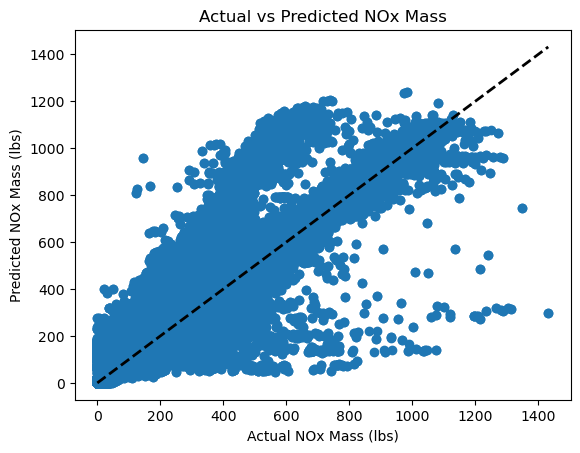

In [ ]:
# model with default parameters (no lags, no unmeasured data, with temps)

# with TX (TF) data

xgb_default_model = xgb.train(params=default_params, dtrain=dtrain, num_boost_round=100)

# dump model
#xgb_default_model.save_model("WY/Hourly/Concatted File/Modeling/XGB/NOx/Trained Models/xgb_default_model_wy_no_lags_with_unmeasured_with_temps.json")

y_pred = xgb_default_model.predict(dtest)

# set all predictions below 0 to 0
y_pred[y_pred < 0] = 0

y_test = dtest.get_label() # get y_test from dmatrix

print(f"R^2 Score: {r2_score(y_test, y_pred):.4f}")
print(f"Mean Squared Error (MSE): {mean_squared_error(y_test, y_pred):.4f}")
print(f"Root Mean Squared Error (RMSE): {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}")
print(f"Normalized RMSE (by std): {np.sqrt(mean_squared_error(y_test, y_pred)) / np.std(y_test):.4f}")

plt.scatter(y_test, y_pred)
plt.xlabel("Actual NOx Mass (lbs)")
plt.ylabel("Predicted NOx Mass (lbs)")
plt.title("Actual vs Predicted NOx Mass")
plt.plot([min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], 'k--', lw=2)
plt.show()

# performance is slightly improved, but TF bias still persists

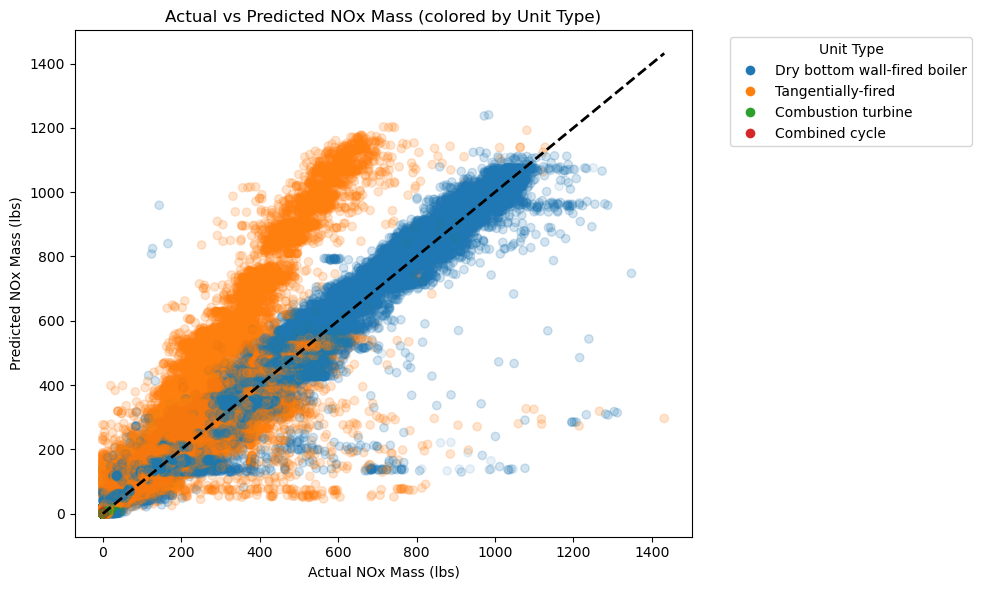

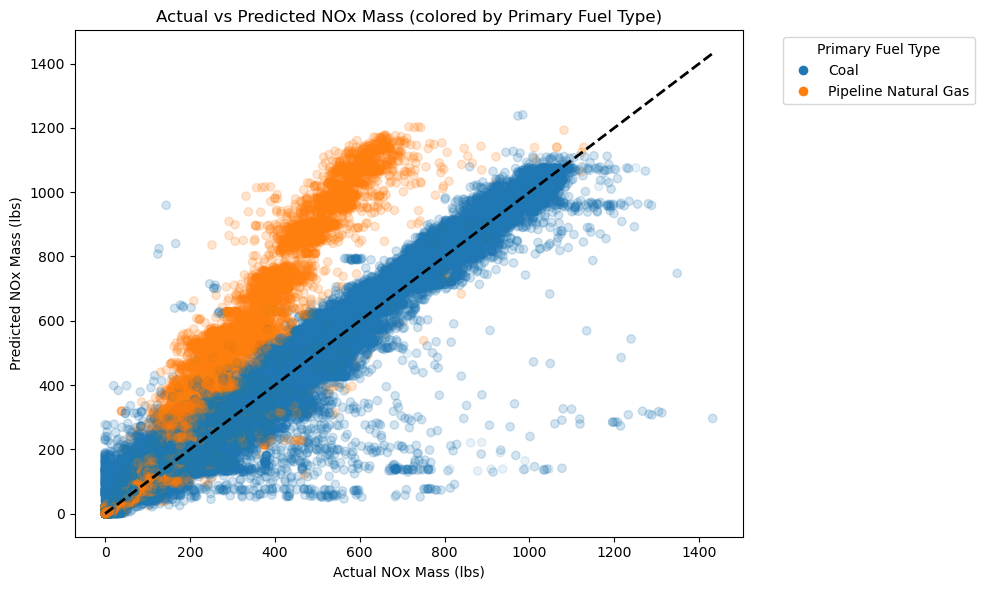

In [57]:
train_mask = (campd_wy_tx["Year"] < 2024) & (campd_wy_tx["NOx Mass (lbs)"].notna())
test_mask = (campd_wy_tx["Year"] == 2024) & (campd_wy_tx["NOx Mass (lbs)"].notna())

unit_types_test = campd_wy_tx.loc[test_mask, "Unit Type"].reset_index(drop=True)

y_test = pd.Series(y_test).reset_index(drop=True)
y_pred = pd.Series(y_pred).reset_index(drop=True)

unique_unit_types = unit_types_test.unique()
palette = sns.color_palette("tab10", len(unique_unit_types))  
color_mapping = dict(zip(unique_unit_types, palette))
colors = unit_types_test.map(color_mapping)

plt.figure(figsize=(10, 6))
scatter = plt.scatter(y_test, y_pred, c=colors, alpha=0.1)
plt.xlabel("Actual NOx Mass (lbs)")
plt.ylabel("Predicted NOx Mass (lbs)")
plt.title("Actual vs Predicted NOx Mass (colored by Unit Type)")
plt.plot(
    [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())],
    [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())],
    'k--', lw=2
)

handles = [plt.Line2D([0], [0], marker='o', color='w', label=ut,
                      markerfacecolor=color_mapping[ut], markersize=8)
           for ut in unique_unit_types]
plt.legend(handles=handles, title="Unit Type", bbox_to_anchor=(1.05, 1), loc='upper left')

plt.tight_layout()
plt.show()

#####################################################

train_mask = (campd_wy_tx["Year"] < 2024) & (campd_wy_tx["NOx Mass (lbs)"].notna())
test_mask = (campd_wy_tx["Year"] == 2024) & (campd_wy_tx["NOx Mass (lbs)"].notna())

fuel_types_test = campd_wy_tx.loc[test_mask, "Primary Fuel Type"].reset_index(drop=True)

y_test = pd.Series(y_test).reset_index(drop=True)
y_pred = pd.Series(y_pred).reset_index(drop=True)

unique_fuel_types = fuel_types_test.unique()
palette = sns.color_palette("tab10", len(unique_fuel_types))  
color_mapping = dict(zip(unique_fuel_types, palette))
colors = fuel_types_test.map(color_mapping)

plt.figure(figsize=(10, 6))
scatter = plt.scatter(y_test, y_pred, c=colors, alpha=0.1)
plt.xlabel("Actual NOx Mass (lbs)")
plt.ylabel("Predicted NOx Mass (lbs)")
plt.title("Actual vs Predicted NOx Mass (colored by Primary Fuel Type)")
plt.plot(
    [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())],
    [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())],
    'k--', lw=2
)

handles = [plt.Line2D([0], [0], marker='o', color='w', label=ut,
                      markerfacecolor=color_mapping[ut], markersize=8)
           for ut in unique_fuel_types]
plt.legend(handles=handles, title="Primary Fuel Type", bbox_to_anchor=(1.05, 1), loc='upper left')

plt.tight_layout()
plt.show()




R^2 Score: 0.8808
Mean Squared Error (MSE): 5531.6401
Root Mean Squared Error (RMSE): 74.3750
Normalized RMSE (by std): 0.3453


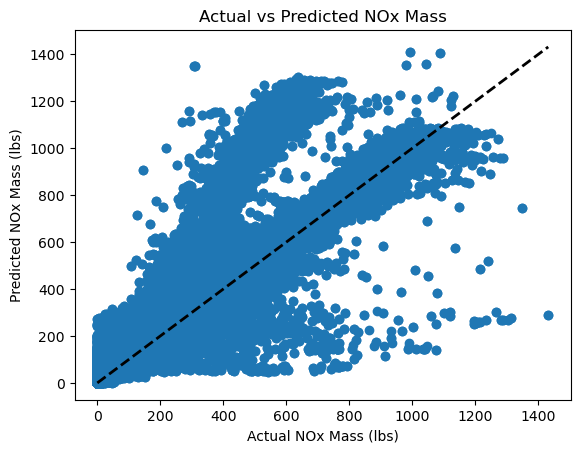

In [ ]:
# model with default parameters (no lags, no unmeasured data, with temps)

# with NY TF data

xgb_default_model = xgb.train(params=default_params, dtrain=dtrain, num_boost_round=100)

# dump model
#xgb_default_model.save_model("WY/Hourly/Concatted File/Modeling/XGB/NOx/Trained Models/xgb_default_model_wy_no_lags_with_unmeasured_with_temps.json")

y_pred = xgb_default_model.predict(dtest)

# set all predictions below 0 to 0
y_pred[y_pred < 0] = 0

y_test = dtest.get_label() # get y_test from dmatrix

print(f"R^2 Score: {r2_score(y_test, y_pred):.4f}")
print(f"Mean Squared Error (MSE): {mean_squared_error(y_test, y_pred):.4f}")
print(f"Root Mean Squared Error (RMSE): {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}")
print(f"Normalized RMSE (by std): {np.sqrt(mean_squared_error(y_test, y_pred)) / np.std(y_test):.4f}")

plt.scatter(y_test, y_pred)
plt.xlabel("Actual NOx Mass (lbs)")
plt.ylabel("Predicted NOx Mass (lbs)")
plt.title("Actual vs Predicted NOx Mass")
plt.plot([min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], 'k--', lw=2)
plt.show()

# actually performs worse than the model trained solely on WY data

<h6>2. Train: WY + ND + MT; Test: WY</h6>

-> Use supplementary training data from ND and MT to see if that improves model performance when predicting WY 2024

In [13]:
campd_nd = pd.read_csv("WY/Hourly/Concatted File/Modeling/XGB/NOx/nd_2019_2024_complete_cleaned_Full_manually_encoded", dtype=campd_type_dict)

In [ ]:
nd_control_cols = ['Dry Low NOx Burners',
       'Low NOx Burner Technology (Dry Bottom only)',
       'Low NOx Burner Technology w/ Closed-coupled/Separated OFA',
       'Nothing', 'Overfire Air', 'Selective Catalytic Reduction',
       'Selective Non-catalytic Reduction', 'Water Injection']
nd_code_cols = ['ARP', 'MATS', 'NSPS4T']
cyclical_cols = ['Hour_sin', 'Hour_cos', 'Day_sin',
       'Day_cos', 'Month_sin', 'Month_cos']
lag_cols = [
    "lag_1_hour",
    "lag_2_hours",
    "lag_1_day",
    "lag_2_days",
    "lag_1_week",
    "lag_1_month",
    "lag_1_year"
       ]

In [ ]:
# features
num_features = ['Gross Load (MW)', 
                'Heat Input (mmBtu)',
                'Latitude', 'Longitude',
                'Nameplate Capacity (MWe)', 'hourly_capacity_factor',
                'hourly_ramping_factor',
                'Summer Capacity (MW)',
                'Winter Capacity (MW)', 
                'Minimum Load (MW)', 
                 'Year',
                 'Temperature (F)'] + lag_cols

unencoded_cat_features = ['Month', 'Hour', 'Day',
                    'Source Category', 
                    'NOx Phase', 'Unit Type', 'Primary Fuel Type', 
                    'Secondary Fuel Type'] 

encoded_cat_features = list(nd_control_cols) + list(nd_code_cols) # for passthrough of the manually one-hot encoded cols

target_variable = "NOx Mass (lbs)"

# sort to put it in appropriate time series format
campd_nd = campd_nd.sort_values(by=["datetime","Facility ID", "Unit ID"])

# split manually by year 2024
X_train_nd = campd_nd[(campd_nd["Year"] < 2024) & (campd_nd["NOx Mass (lbs)"].notna())][num_features + unencoded_cat_features + encoded_cat_features]
y_train_nd = campd_nd[(campd_nd["Year"] < 2024) & (campd_nd["NOx Mass (lbs)"].notna())][target_variable]  
X_test_nd = campd_nd[(campd_nd["Year"] == 2024) & (campd_nd["NOx Mass (lbs)"].notna())][num_features + unencoded_cat_features + encoded_cat_features]
y_test_nd = campd_nd[(campd_nd["Year"] ==  2024) & (campd_nd["NOx Mass (lbs)"].notna())][target_variable]

preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), unencoded_cat_features), 
        ('num', 'passthrough', num_features),
        ('encoded', 'passthrough', encoded_cat_features)  # add the pre-encoded features 
    ]
)

preprocessor.set_output(transform='pandas') # transform pandas.NA values to normal nan

X_train_nd = preprocessor.fit_transform(X_train_nd)
X_test_nd = preprocessor.transform(X_test_nd)

X_train_nd.to_csv("ND/Hourly/Concatted File/Modeling/XGB/NOx/X_train_processed_nd", index=False)
X_test_nd.to_csv("ND/Hourly/Concatted File/Modeling/XGB/NOx/X_test_processed_nd", index=False)
y_train_nd.to_csv("ND/Hourly/Concatted File/Modeling/XGB/NOx/y_train_nd", index=False)
y_test_nd.to_csv("ND/Hourly/Concatted File/Modeling/XGB/NOx/y_test_nd", index=False)

In [21]:
# concat with wyoming data

encoded_lag_cols = [
    "encoded__lag_1_hour",
    "encoded__lag_2_hours",
    "encoded__lag_1_day",
    "encoded__lag_2_days",
    "encoded__lag_1_week",
    "encoded__lag_1_month",
    "encoded__lag_1_year"
       ]

X_train_wy = pd.read_csv("WY/Hourly/Concatted File/Modeling/XGB/NOx/X_train_processed", dtype=campd_type_dict).drop(columns=encoded_lag_cols, axis=1)
X_test_wy = pd.read_csv("WY/Hourly/Concatted File/Modeling/XGB/NOx/X_test_processed", dtype=campd_type_dict).drop(columns=encoded_lag_cols, axis=1)
y_train_wy = pd.read_csv("WY/Hourly/Concatted File/Modeling/XGB/NOx/y_train", dtype=campd_type_dict)
y_test_wy = pd.read_csv("WY/Hourly/Concatted File/Modeling/XGB/NOx/y_test", dtype=campd_type_dict)
X_train = pd.concat([X_train_nd.drop(columns=encoded_lag_cols, axis=1), X_train_wy])
X_test = pd.concat([X_test_nd.drop(columns=encoded_lag_cols, axis=1), X_test_wy])
y_train = pd.concat([y_train_nd, y_train_wy])
y_test = pd.concat([y_test_nd, y_test_wy])

In [ ]:
campd_mt = pd.read_csv("WY/Hourly/Concatted File/Modeling/XGB/NOx/mt_2019_2024_complete_cleaned_Full_manually_encoded", dtype=campd_type_dict)

In [60]:
mt_control_cols = ['Dry Low NOx Burners', 'Low NOx Burner Technology (Dry Bottom only)',
       'Low NOx Burner Technology w/ Closed-coupled OFA',
       'Low NOx Burner Technology w/ Closed-coupled/Separated OFA',
       'Selective Catalytic Reduction', 'Water Injection']
mt_code_cols = ['ARP', 'MATS']
cyclical_cols = ['Hour_sin', 'Hour_cos', 'Day_sin',
       'Day_cos', 'Month_sin', 'Month_cos']
lag_cols = [
    "lag_1_hour",
    "lag_2_hours",
    "lag_1_day",
    "lag_2_days",
    "lag_1_week",
    "lag_1_month",
    "lag_1_year"
]

In [ ]:
# features
num_features = ['Gross Load (MW)', 
                    'Heat Input (mmBtu)',
                'Latitude', 'Longitude',
                'Nameplate Capacity (MWe)', 'hourly_capacity_factor',
                'hourly_ramping_factor',
                'Summer Capacity (MW)',
                'Winter Capacity (MW)', 
                'Minimum Load (MW)', 
                'Temperature (F)',
                 'Year'] + lag_cols

unencoded_cat_features = ['Month', 'Hour', 'Day', 
                    'Source Category', 
                    'NOx Phase', 'Unit Type', 'Primary Fuel Type', 
                    'Secondary Fuel Type'] 

encoded_cat_features = list(mt_control_cols) + list(mt_code_cols) # for passthrough of the manually one-hot encoded cols

target_variable = "NOx Mass (lbs)"

# sort to put it in appropriate time series format
campd_mt = campd_mt.sort_values(by=["datetime","Facility ID", "Unit ID"])

# split manually by year 2024
X_train_mt = campd_mt[(campd_mt["Year"] < 2024) & (campd_mt["NOx Mass (lbs)"].notna())][num_features + unencoded_cat_features + encoded_cat_features]
y_train_mt = campd_mt[(campd_mt["Year"] < 2024) & (campd_mt["NOx Mass (lbs)"].notna())][target_variable]  
X_test_mt = campd_mt[(campd_mt["Year"] == 2024) & (campd_mt["NOx Mass (lbs)"].notna())][num_features + unencoded_cat_features + encoded_cat_features]
y_test_mt = campd_mt[(campd_mt["Year"] ==  2024) & (campd_mt["NOx Mass (lbs)"].notna())][target_variable]

preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), unencoded_cat_features), 
        ('num', 'passthrough', num_features),
        ('encoded', 'passthrough', encoded_cat_features)  # add the pre-encoded features 
    ]
)

preprocessor.set_output(transform='pandas') # transform pandas.NA values to normal nan


ColumnTransformer(transformers=[('cat',
                                 OneHotEncoder(handle_unknown='ignore',
                                               sparse_output=False),
                                 ['Month', 'Hour', 'Day', 'Source Category',
                                  'NOx Phase', 'Unit Type', 'Primary Fuel Type',
                                  'Secondary Fuel Type']),
                                ('num', 'passthrough',
                                 ['Gross Load (MW)', 'Heat Input (mmBtu)',
                                  'Latitude', 'Longitude',
                                  'Nameplate Capacity (MWe)',
                                  'hourly_capacity_factor',
                                  'hourly_ramping_facto...
                                  'Temperature (F)', 'Year']),
                                ('encoded', 'passthrough',
                                 ['Dry Low NOx Burners',
                                  'Low NOx Burner Technology (Dry Bottom only)',
                                  'Low NOx Burner Technology w/ Closed-coupled '
                                  'OFA',
                                  'Low NOx Burner Technology w/ '
                                  'Closed-coupled/Separated OFA',
                                  'Selective Catalytic Reduction',
                                  'Water Injection', 'ARP', 'MATS',
                                  'lag_1_hour', 'lag_2_hours', 'lag_1_day',
                                  'lag_2_days', 'lag_1_week', 'lag_1_month',
                                  'lag_1_year'])])

In [62]:
X_train_mt = preprocessor.fit_transform(X_train_mt)
X_test_mt = preprocessor.transform(X_test_mt)

In [64]:
X_train_mt.to_csv("MT/Hourly/Concatted File/Modeling/XGB/NOx/X_train_processed_mt", index=False)
X_test_mt.to_csv("MT/Hourly/Concatted File/Modeling/XGB/NOx/X_test_processed_mt", index=False)
y_train_mt.to_csv("MT/Hourly/Concatted File/Modeling/XGB/NOx/y_train_mt", index=False)
y_test_mt.to_csv("MT/Hourly/Concatted File/Modeling/XGB/NOx/y_test_mt", index=False)

In [ ]:
# concat wyoming, north dakota, montana data

X_train_wy = pd.read_csv("WY/Hourly/Concatted File/Modeling/XGB/NOx/X_train_processed", dtype=campd_type_dict).drop(columns=encoded_lag_cols, axis=1)
X_test_wy = pd.read_csv("WY/Hourly/Concatted File/Modeling/XGB/NOx/X_test_processed", dtype=campd_type_dict).drop(columns=encoded_lag_cols, axis=1)
y_train_wy = pd.read_csv("WY/Hourly/Concatted File/Modeling/XGB/NOx/y_train", dtype=campd_type_dict)
y_test_wy = pd.read_csv("WY/Hourly/Concatted File/Modeling/XGB/NOx/y_test", dtype=campd_type_dict)

X_train_nd = pd.read_csv("ND/Hourly/Concatted File/Modeling/XGB/NOx/X_train_processed_nd", dtype=campd_type_dict)#.drop(columns=encoded_lag_cols, axis=1)
X_test_nd = pd.read_csv("ND/Hourly/Concatted File/Modeling/XGB/NOx/X_test_processed_nd", dtype=campd_type_dict)#.drop(columns=encoded_lag_cols, axis=1)
y_train_nd = pd.read_csv("ND/Hourly/Concatted File/Modeling/XGB/NOx/y_train_nd", dtype=campd_type_dict)
y_test_nd = pd.read_csv("ND/Hourly/Concatted File/Modeling/XGB/NOx/y_test_nd", dtype=campd_type_dict)

X_train_mt = pd.read_csv("MT/Hourly/Concatted File/Modeling/XGB/NOx/X_train_processed_mt", dtype=campd_type_dict)#.drop(columns=encoded_lag_cols, axis=1)
X_test_mt = pd.read_csv("MT/Hourly/Concatted File/Modeling/XGB/NOx/X_test_processed_mt", dtype=campd_type_dict)#.drop(columns=encoded_lag_cols, axis=1)
y_train_mt = pd.read_csv("MT/Hourly/Concatted File/Modeling/XGB/NOx/y_train_mt", dtype=campd_type_dict)
y_test_mt = pd.read_csv("MT/Hourly/Concatted File/Modeling/XGB/NOx/y_test_mt", dtype=campd_type_dict)

X_train = pd.concat([X_train_nd, X_train_wy, X_train_mt])
X_test = pd.concat([X_test_nd, X_test_wy, X_test_mt])
y_train = pd.concat([y_train_nd, y_train_wy, y_train_mt])
y_test = pd.concat([y_test_nd, y_test_wy, y_test_mt])


In [ ]:
# fill categorical columns with 0 if nan
X_train.loc[:, X_train.columns.str.startswith("cat__")] = X_train.loc[:, X_train.columns.str.startswith("cat__")].fillna(0)
X_train.loc[:, X_train.columns.str.startswith("encoded__")] = X_train.loc[:, X_train.columns.str.startswith("encoded__")].fillna(0)
X_test.loc[:, X_test.columns.str.startswith("cat__")] = X_test.loc[:, X_test.columns.str.startswith("cat__")].fillna(0)
X_test.loc[:, X_test.columns.str.startswith("encoded__")] = X_test.loc[:, X_test.columns.str.startswith("encoded__")].fillna(0)

In [ ]:
X_train.to_csv("WY/Hourly/Concatted File/Modeling/XGB/NOx/X_train_processed_all", index=False)
X_test.to_csv("WY/Hourly/Concatted File/Modeling/XGB/NOx/X_test_processed_all", index=False)
y_train.to_csv("WY/Hourly/Concatted File/Modeling/XGB/NOx/y_train_all", index=False)
y_test.to_csv("WY/Hourly/Concatted File/Modeling/XGB/NOx/y_test_all", index=False)

In [ ]:
X_train = pd.read_csv("WY/Hourly/Concatted File/Modeling/XGB/NOx/X_train_processed_all")
X_test = pd.read_csv("WY/Hourly/Concatted File/Modeling/XGB/NOx/X_test_processed_all")
y_train = pd.read_csv("WY/Hourly/Concatted File/Modeling/XGB/NOx/y_train_all")
y_test = pd.read_csv("WY/Hourly/Concatted File/Modeling/XGB/NOx/y_test_all")

In [ ]:
dtrain = xgb.DMatrix(X_train, label=y_train)
dtest_wy = xgb.DMatrix(X_test_wy, label=y_test_wy)

R^2 Score: 0.8773
Mean Squared Error (MSE): 5694.6909
Root Mean Squared Error (RMSE): 75.4632
Normalized RMSE (by std): 0.3503


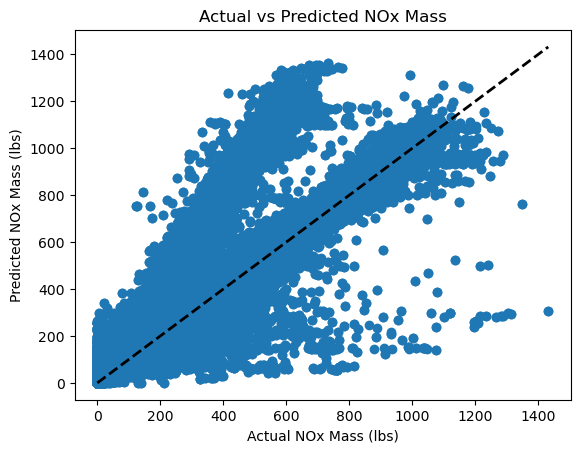

In [ ]:
# model with default parameters (no lags, no unmeasured data, with temps)

# WY + ND + MT

xgb_default_model = xgb.train(params=default_params, dtrain=dtrain, num_boost_round=100)

# dump model
#xgb_default_model.save_model("WY/Hourly/Concatted File/Modeling/XGB/NOx/Trained Models/xgb_default_model_wy_no_lags_with_unmeasured_WITH_ND_MT.json")

y_pred = xgb_default_model.predict(dtest_wy)

# set all predictions below 0 to 0
y_pred[y_pred < 0] = 0

y_test = dtest_wy.get_label() # get y_test from dmatrix

print(f"R^2 Score: {r2_score(y_test, y_pred):.4f}")
print(f"Mean Squared Error (MSE): {mean_squared_error(y_test, y_pred):.4f}")
print(f"Root Mean Squared Error (RMSE): {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}")
print(f"Normalized RMSE (by std): {np.sqrt(mean_squared_error(y_test, y_pred)) / np.std(y_test):.4f}")

plt.scatter(y_test, y_pred)
plt.xlabel("Actual NOx Mass (lbs)")
plt.ylabel("Predicted NOx Mass (lbs)")
plt.title("Actual vs Predicted NOx Mass")
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'k--', lw=2)
plt.show()

# model performs worse than that with only WY training data

<h6>3. Train: WY; Test: ND/MT</h6>

-> Use WY-trained model (2019-2023) to predict MT and ND data (2024)

- first we explore some of the differences between unit types and fuel mixes between states
- for ND, we build models both when predicting on unseen unit types and only on seen types

In [38]:
X_train_mt = pd.read_csv("MT/Hourly/Concatted File/Modeling/XGB/NOx/X_train_processed_mt")
X_test_mt = pd.read_csv("MT/Hourly/Concatted File/Modeling/XGB/NOx/X_test_processed_mt")
y_train_mt = pd.read_csv("MT/Hourly/Concatted File/Modeling/XGB/NOx/y_train_mt")
y_test_mt = pd.read_csv("MT/Hourly/Concatted File/Modeling/XGB/NOx/y_test_mt")

In [ ]:
# MT has generally higher emissions and greater sd than WY

print("WY:")
print(y_test_wy.describe())
print("\nMT:")
print(y_test_mt.describe())

WY:
       NOx Mass (lbs)
count       435797.00
mean           181.25
std            215.40
min              0.00
25%              2.28
50%            135.24
75%            255.51
max           1431.70

MT:
       NOx Mass (lbs)
count       150017.00
mean           328.05
std            510.09
min              0.00
25%              3.80
50%              7.88
75%            695.30
max           1837.89


In [ ]:
# similar fuel mixes
# overlapping unit types (Combined cycle is unique to WY)

print("WY:")
display(campd_df.groupby(by="Unit Type")["NOx Mass (lbs)"].sum().sort_values(ascending=False))

display(campd_df.groupby(by="Primary Fuel Type")["NOx Mass (lbs)"].sum().sort_values(ascending=False))

print("MT:")
display(campd_mt.groupby(by="Unit Type")["NOx Mass (lbs)"].sum().sort_values(ascending=False))

display(campd_mt.groupby(by="Primary Fuel Type")["NOx Mass (lbs)"].sum().sort_values(ascending=False))


WY:


Unit Type
Dry bottom wall-fired boiler   353806176.00
Tangentially-fired             227806976.00
Combustion turbine                665021.12
Combined cycle                    262930.84
Name: NOx Mass (lbs), dtype: float32

Primary Fuel Type
Coal                         568704192.00
Pipeline Natural Gas          12357907.00
Coal, Pipeline Natural Gas     1478991.12
Name: NOx Mass (lbs), dtype: float32

MT:


Unit Type
Tangentially-fired             324778550.45
Dry bottom wall-fired boiler     7165974.64
Combustion turbine               3512727.20
Name: NOx Mass (lbs), dtype: float64

Primary Fuel Type
Coal                   331944525.09
Pipeline Natural Gas     3512727.20
Name: NOx Mass (lbs), dtype: float64

In [67]:
X_train_nd = pd.read_csv("ND/Hourly/Concatted File/Modeling/XGB/NOx/X_train_processed_nd")
X_test_nd = pd.read_csv("ND/Hourly/Concatted File/Modeling/XGB/NOx/X_test_processed_nd")
y_train_nd = pd.read_csv("ND/Hourly/Concatted File/Modeling/XGB/NOx/y_train_nd")
y_test_nd = pd.read_csv("ND/Hourly/Concatted File/Modeling/XGB/NOx/y_test_nd")

In [ ]:
# ND has generally higher emissions and greater std

print("WY:")
print(y_test_wy.describe())
print("\nND:")
print(y_test_nd.describe())

WY:
       NOx Mass (lbs)
count       435797.00
mean           181.25
std            215.40
min              0.00
25%              2.28
50%            135.24
75%            255.51
max           1431.70

ND:
       NOx Mass (lbs)
count       127867.00
mean           445.19
std            524.37
min              0.00
25%              4.07
50%            254.16
75%            776.11
max           3154.33


In [ ]:
# both have similar fuel mixes of coal and natural gas
# but ND has a greater variety in unit types

print("WY:")
display(campd_df.groupby(by="Unit Type")["NOx Mass (lbs)"].sum().sort_values(ascending=False))

display(campd_df.groupby(by="Primary Fuel Type")["NOx Mass (lbs)"].sum().sort_values(ascending=False))

print("ND:")
display(campd_nd.groupby(by="Unit Type")["NOx Mass (lbs)"].sum().sort_values(ascending=False))

display(campd_nd.groupby(by="Primary Fuel Type")["NOx Mass (lbs)"].sum().sort_values(ascending=False))

WY:


Unit Type
Dry bottom wall-fired boiler   353806176.00
Tangentially-fired             227806976.00
Combustion turbine                665021.12
Combined cycle                    262930.84
Name: NOx Mass (lbs), dtype: float32

Primary Fuel Type
Coal                         568704192.00
Pipeline Natural Gas          12357907.00
Coal, Pipeline Natural Gas     1478991.12
Name: NOx Mass (lbs), dtype: float32

ND:


Unit Type
Cyclone boiler                              212893248.00
Tangentially-fired                          117202432.00
Dry bottom wall-fired boiler                 10316772.00
Bubbling fluidized bed boiler                 6133157.50
Circulating fluidized bed boiler              2415501.75
Combustion turbine                            1230774.75
Combustion turbine (Started Aug 04, 2021)        1057.01
Name: NOx Mass (lbs), dtype: float32

Primary Fuel Type
Coal                   348961120.00
Pipeline Natural Gas     1231831.75
Name: NOx Mass (lbs), dtype: float32

In [ ]:
# get the wy-trained model
xgb_default_model_no_lags = xgb.Booster()
xgb_default_model_no_lags.load_model("WY/Hourly/Concatted File/Modeling/XGB/NOx/Trained Models/xgb_default_model_wy_no_lags_with_unmeasured_with_temps.json")

In [ ]:
# remove lag columns for mt and nd
encoded_lag_cols = [
    "encoded__lag_1_hour",
    "encoded__lag_2_hours",
    "encoded__lag_1_day",
    "encoded__lag_2_days",
    "encoded__lag_1_week",
    "encoded__lag_1_month",
    "encoded__lag_1_year"
       ]

X_test_mt = X_test_mt.drop(columns=encoded_lag_cols)
X_test_nd = X_test_nd.drop(columns=encoded_lag_cols)

In [ ]:
# mt is very similar with only one new Secondary Fuel, one new NOx Control, and one new NOx control combination compared to wy
# nd shows greater variety, particulary due to more unit types

print("Columns only in mt, not wy")
print(set(X_test_mt.columns) - set(xgb_default_model_no_lags.feature_names))

print("Columns only in nd, not wy")
print(set(X_test_nd.columns) - set(xgb_default_model_no_lags.feature_names))

Columns only in mt, not wy
{'cat__Secondary Fuel Type_Diesel Oil', 'encoded__Water Injection', 'encoded__Low NOx Burner Technology w/ Closed-coupled/Separated OFA'}
Columns only in nd, not wy
{'cat__Secondary Fuel Type_Diesel Oil', 'encoded__Water Injection', 'cat__Unit Type_Bubbling fluidized bed boiler', 'cat__Source Category_Cogeneration', 'encoded__Low NOx Burner Technology w/ Closed-coupled/Separated OFA', 'cat__Unit Type_Cyclone boiler', 'cat__Unit Type_Combustion turbine (Started Aug 04, 2021)', 'cat__Secondary Fuel Type_Liquified Petroleum Gas, Pipeline Natural Gas', 'encoded__NSPS4T', 'cat__Unit Type_Circulating fluidized bed boiler'}


In [ ]:
# adjust columns such that nd/mt has the same features as wy, if a (categorical) column exists in wy, but not in nd/mt we set it 0 for all rows
# if it exists in nd/mt, but not in wy we drop it

wy_features = xgb_default_model_no_lags.feature_names
nd_features = X_test_nd.columns.tolist()
mt_features = X_test_mt.columns.tolist()

X_test_nd_adjusted = X_test_nd.copy()
X_test_mt_adjusted = X_test_mt.copy()

# Features to add (with 0s)
features_to_add = list(set(wy_features) - set(nd_features)) # features in wy, but not nd
for feature in features_to_add:
    X_test_nd_adjusted[feature] = 0
features_to_add = list(set(wy_features) - set(mt_features)) # features in wy, but not mt
for feature in features_to_add:
    X_test_mt_adjusted[feature] = 0

# Features to drop
features_to_drop = list(set(nd_features) - set(wy_features)) # features in nd, but not wy
X_test_nd_adjusted.drop(columns=features_to_drop, inplace=True)
features_to_drop = list(set(mt_features) - set(wy_features)) # features in mt, but not wy
X_test_mt_adjusted.drop(columns=features_to_drop, inplace=True)

# Reorder the columns to match wy_features
X_test_nd_adjusted = X_test_nd_adjusted[wy_features]
X_test_mt_adjusted = X_test_mt_adjusted[wy_features]

In [ ]:
# shared unit types across wy, nd, and mt
shared_unit_types_nd = list(set(campd_nd["Unit Type"]).intersection(set(campd_df["Unit Type"].unique())))
shared_unit_types_mt = list(set(campd_mt["Unit Type"]).intersection(set(campd_df["Unit Type"].unique())))
print(shared_unit_types_nd)
print(shared_unit_types_mt)

['Tangentially-fired', 'Combustion turbine', 'Dry bottom wall-fired boiler']
['Tangentially-fired', 'Combustion turbine', 'Dry bottom wall-fired boiler']


In [ ]:
# filter nd data to only include units part of wy training data
X_test_nd_adjusted_filtered = X_test_nd_adjusted[(X_test_nd_adjusted["cat__Unit Type_Tangentially-fired"] == 1) | (X_test_nd_adjusted["cat__Unit Type_Combustion turbine"] == 1) | (X_test_nd_adjusted["cat__Unit Type_Dry bottom wall-fired boiler"] == 1)]
y_test_nd_filtered = y_test_nd[X_test_nd_adjusted_filtered.index]

In [ ]:
dtest_mt_adjusted = xgb.DMatrix(X_test_mt_adjusted, label=y_test_mt)

dtest_nd_adjusted = xgb.DMatrix(X_test_nd_adjusted, label=y_test_nd)
dtest_nd_adjusted_filtered = xgb.DMatrix(X_test_nd_adjusted_filtered, label=y_test_nd_filtered)

R^2 Score: 0.9469
Mean Squared Error (MSE): 13810.8203
Root Mean Squared Error (RMSE): 117.5194
Normalized RMSE (by std): 0.2304


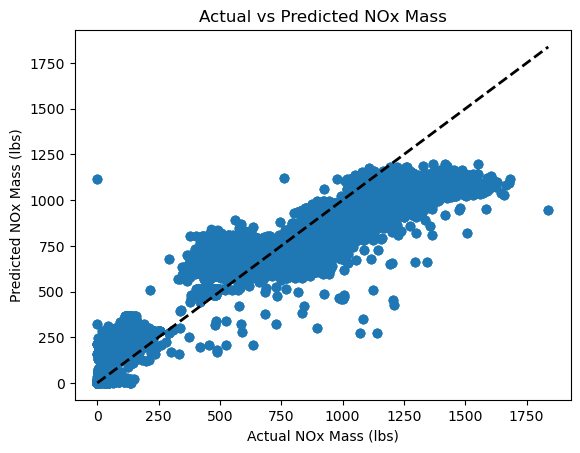

In [ ]:
# model trained on wy data (2019-2023) to predict mt data (no filtering necessary, all units in mt exist in wy)

y_pred = xgb_default_model_no_lags.predict(dtest_mt_adjusted)

# set all predictions below 0 to 0
y_pred[y_pred < 0] = 0

y_test = dtest_mt_adjusted.get_label() # get y_test from dmatrix

print(f"R^2 Score: {r2_score(y_test, y_pred):.4f}")
print(f"Mean Squared Error (MSE): {mean_squared_error(y_test, y_pred):.4f}")
print(f"Root Mean Squared Error (RMSE): {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}")
print(f"Normalized RMSE (by std): {np.sqrt(mean_squared_error(y_test, y_pred)) / np.std(y_test):.4f}")

plt.scatter(y_test, y_pred)
plt.xlabel("Actual NOx Mass (lbs)")
plt.ylabel("Predicted NOx Mass (lbs)")
plt.title("Actual vs Predicted NOx Mass")
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'k--', lw=2)
plt.show()

# model performs very well, even better than the performance of the wy model on its own test data for 2024

R^2 Score: 0.6333
Mean Squared Error (MSE): 100820.1328
Root Mean Squared Error (RMSE): 317.5219
Normalized RMSE (by std): 0.6055


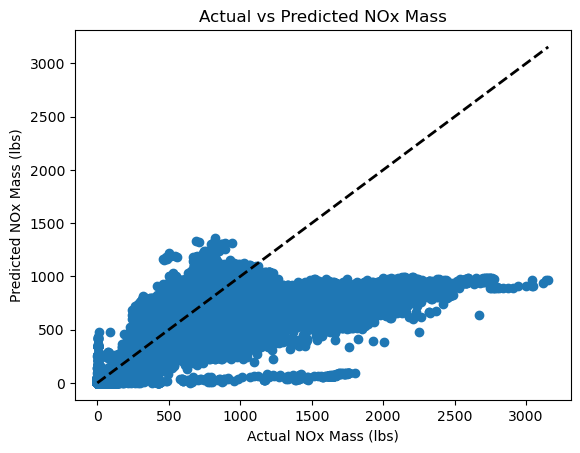

In [ ]:
# model trained on wy data (2019-2023) to predict nd data (unfiltered -> unseen unit types are kept)

y_pred = xgb_default_model_no_lags.predict(dtest_nd_adjusted)

# set all predictions below 0 to 0
y_pred[y_pred < 0] = 0

y_test = dtest_nd_adjusted.get_label() # get y_test from dmatrix

print(f"R^2 Score: {r2_score(y_test, y_pred):.4f}")
print(f"Mean Squared Error (MSE): {mean_squared_error(y_test, y_pred):.4f}")
print(f"Root Mean Squared Error (RMSE): {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}")
print(f"Normalized RMSE (by std): {np.sqrt(mean_squared_error(y_test, y_pred)) / np.std(y_test):.4f}")

plt.scatter(y_test, y_pred)
plt.xlabel("Actual NOx Mass (lbs)")
plt.ylabel("Predicted NOx Mass (lbs)")
plt.title("Actual vs Predicted NOx Mass")
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'k--', lw=2)
plt.show()

# model underperforms significantly

R^2 Score: 0.8074
Mean Squared Error (MSE): 20011.9648
Root Mean Squared Error (RMSE): 141.4637
Normalized RMSE (by std): 0.4389


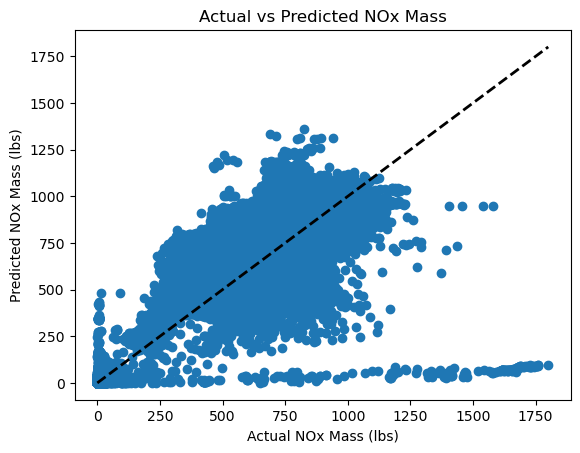

In [ ]:
# model trained on wy data (2019-2023) to predict nd data (filtered -> only rows of units seen by the wy model are included)

y_pred = xgb_default_model_no_lags.predict(dtest_nd_adjusted_filtered)

# set all predictions below 0 to 0
y_pred[y_pred < 0] = 0

y_test = dtest_nd_adjusted_filtered.get_label() # get y_test from dmatrix

print(f"R^2 Score: {r2_score(y_test, y_pred):.4f}")
print(f"Mean Squared Error (MSE): {mean_squared_error(y_test, y_pred):.4f}")
print(f"Root Mean Squared Error (RMSE): {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}")
print(f"Normalized RMSE (by std): {np.sqrt(mean_squared_error(y_test, y_pred)) / np.std(y_test):.4f}")

plt.scatter(y_test, y_pred)
plt.xlabel("Actual NOx Mass (lbs)")
plt.ylabel("Predicted NOx Mass (lbs)")
plt.title("Actual vs Predicted NOx Mass")
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'k--', lw=2)
plt.show()

# still underperforms, but big improvement

<h2>Interpretability</h2>

<h5>Read-in Models</h5>

In [ ]:
# load saved models (all models trained exclusively on wy data)

rf_default_model_no_lags = joblib.load("WY/Hourly/Concatted File/Modeling/RF/NOx/Trained Models/rf_default_model_wy_no_lags_with_unmeasured_with_temps.json")

xgb_default_model_with_lags = xgb.Booster()
xgb_default_model_with_lags.load_model("WY/Hourly/Concatted File/Modeling/XGB/NOx/Trained Models/xgb_default_model_wy_with_lags_with_unmeasured_with_temps.json")

xgb_default_model_no_lags = xgb.Booster()
xgb_default_model_no_lags.load_model("WY/Hourly/Concatted File/Modeling/XGB/NOx/Trained Models/xgb_default_model_wy_no_lags_with_unmeasured_with_temps.json")

<h3>RF (model-specific)</h3>

- Mean Decrease in Impurity (MDI) for RF without and with lags

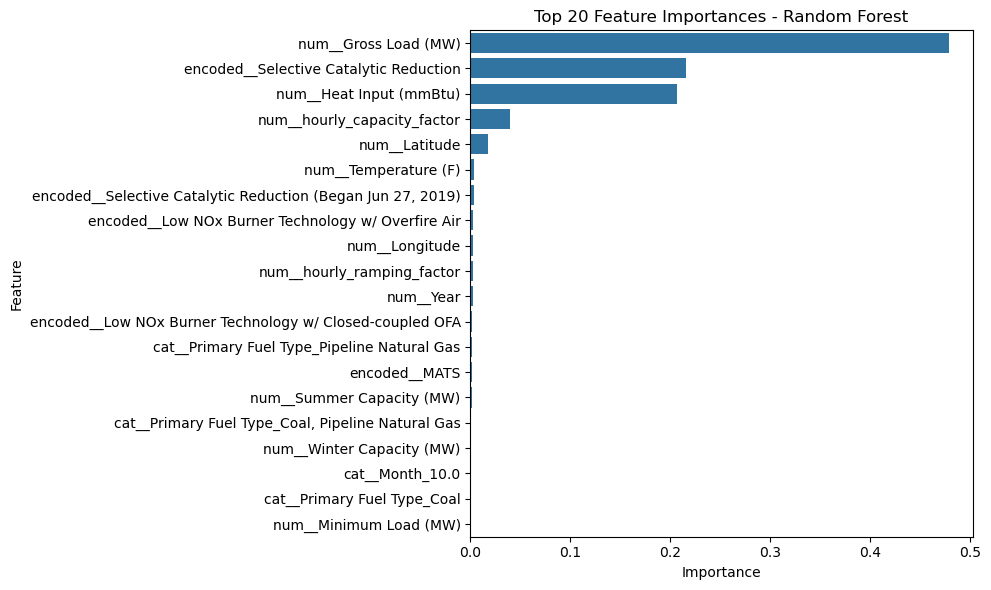

In [85]:
# for default rf model no lags, no unmeasured data, with temps

importances = rf_default_model_no_lags.feature_importances_

feat_imp_df = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': importances
})

feat_imp_df = feat_imp_df.sort_values(by='Importance', ascending=False)

# uses MDI (Mean Decrease in Impurity)
plt.figure(figsize=(10, 6))
sns.barplot(data=feat_imp_df.head(20), x='Importance', y='Feature')
plt.title('Top 20 Feature Importances - Random Forest')
plt.tight_layout()
plt.show()


<h3>XGB (model-specific)</h3>

- Weight, gain, and cover for XGB with and without lags (as well as for the model without lags and without select proxy variables)

<Axes: title={'center': 'Feature importance'}, xlabel='F score', ylabel='Features'>

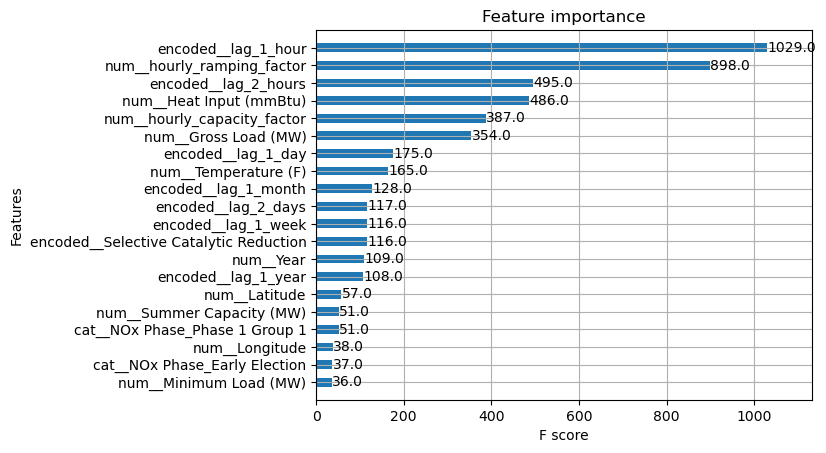

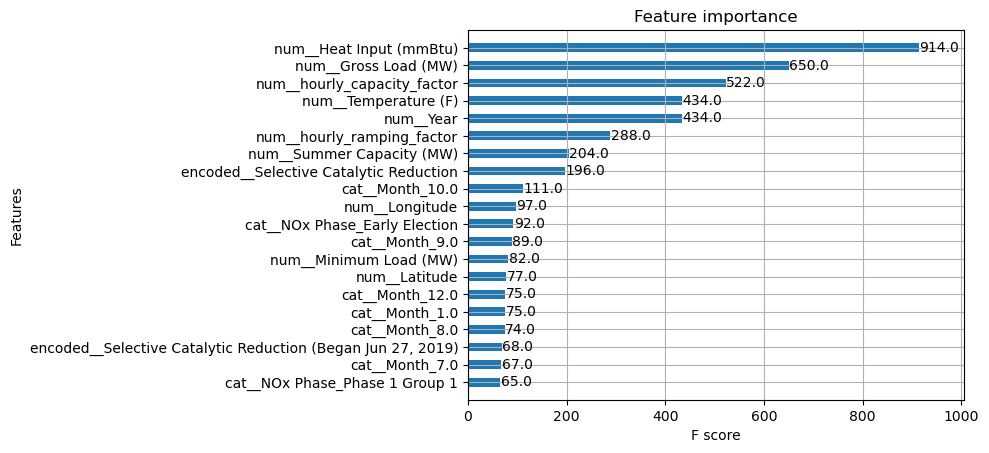

In [88]:
# use weight for feature importance (how often the feature is used in splits)
plot_importance(
    xgb_default_model_with_lags, 
    importance_type='weight',
    max_num_features=20,       
    height=0.5,
    show_values=True,
    grid=True
)

plot_importance(
    xgb_default_model_no_lags, 
    importance_type='weight',
    max_num_features=20,       
    height=0.5,
    show_values=True,
    grid=True
)

<Axes: title={'center': 'Feature importance'}, xlabel='F score', ylabel='Features'>

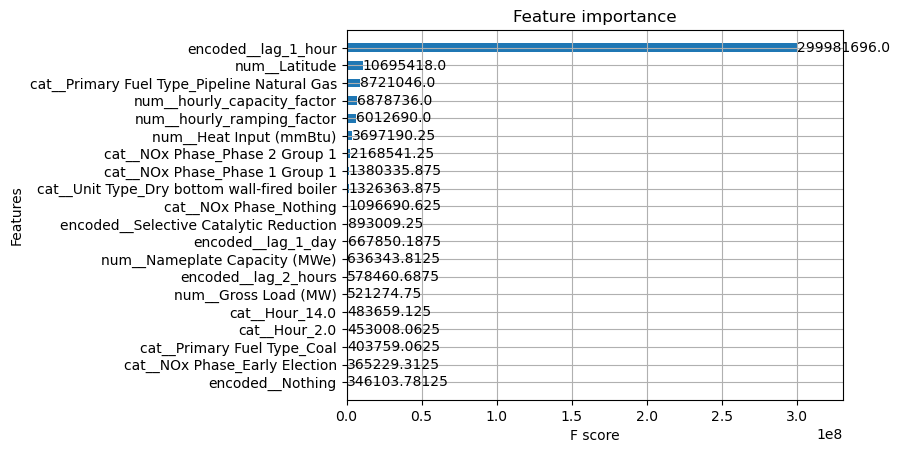

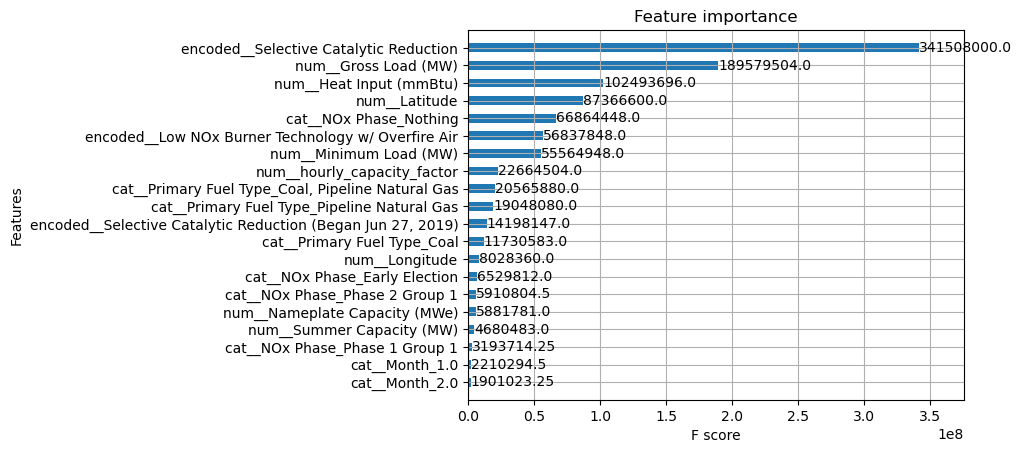

In [89]:
# use gain for feature importance (Average improvement in loss from splits involving that feature)
plot_importance(
    xgb_default_model_with_lags, 
    importance_type='gain',
    max_num_features=20,       
    height=0.5,
    show_values=True,
    grid=True
)

plot_importance(
    xgb_default_model_no_lags, 
    importance_type='gain',
    max_num_features=20,       
    height=0.5,
    show_values=True,
    grid=True
)

<Axes: title={'center': 'Feature importance'}, xlabel='F score', ylabel='Features'>

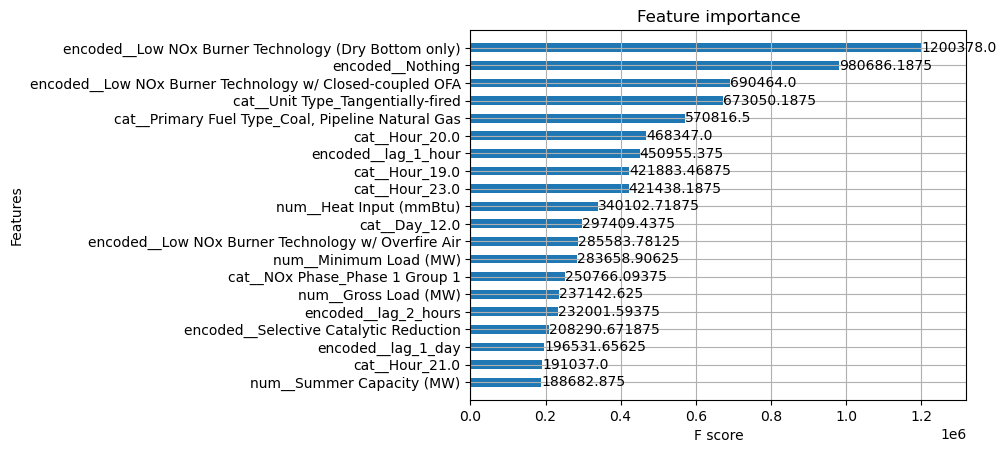

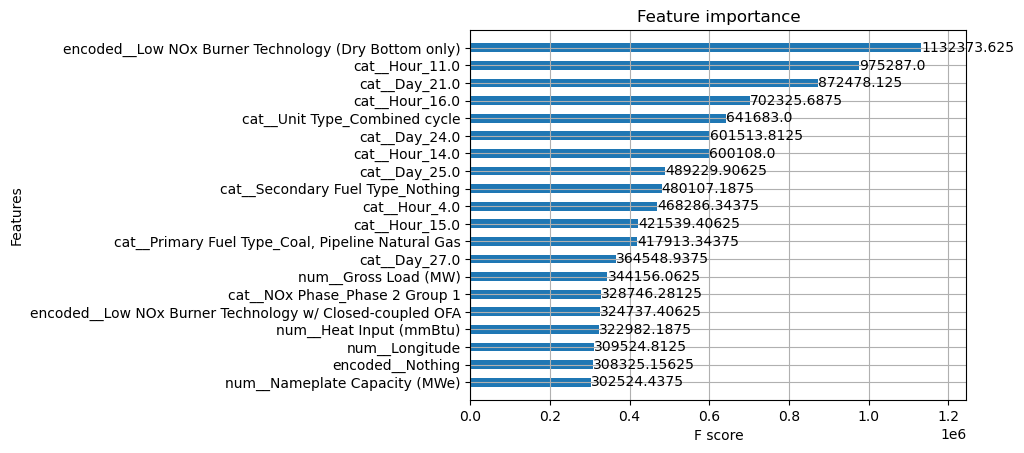

In [90]:
# use cover for feature importance (how many observations are affected by the feature)
plot_importance(
    xgb_default_model_with_lags, 
    importance_type='cover',
    max_num_features=20,       
    height=0.5,
    show_values=True,
    grid=True
)

plot_importance(
    xgb_default_model_no_lags, 
    importance_type='cover',
    max_num_features=20,       
    height=0.5,
    show_values=True,
    grid=True
)

<h3>Permutation Importance</h3>

In [91]:
regressor = XGBRegressor()
regressor._Booster = xgb_default_model_no_lags

<h4>Ungrouped</h4>

In [96]:
result = permutation_importance(regressor, X_test, y_test, n_repeats=3, random_state=42, scoring='neg_mean_squared_error', n_jobs=-1)

importance_df = pd.DataFrame({
    'feature': X_test.columns,
    'importance_mean': result.importances_mean,
    'importance_std': result.importances_std
}).sort_values(by='importance_mean', ascending=False)

display(importance_df)


,feature,importance_mean,importance_std
83,num__Heat Input (mmBtu),"88,480.15",55.27
101,encoded__Selective Catalytic Reduction,"29,652.04",157.12
82,num__Gross Load (MW),"6,717.97",32.34
87,num__hourly_capacity_factor,"5,141.46",44.49
84,num__Latitude,"2,228.13",18.53
...,...,...,...
71,cat__NOx Phase_Phase 2 Group 1,-20.52,3.61
11,cat__Month_12.0,-58.41,0.98
89,num__Summer Capacity (MW),-93.12,5.47
7,cat__Month_8.0,-97.30,0.10


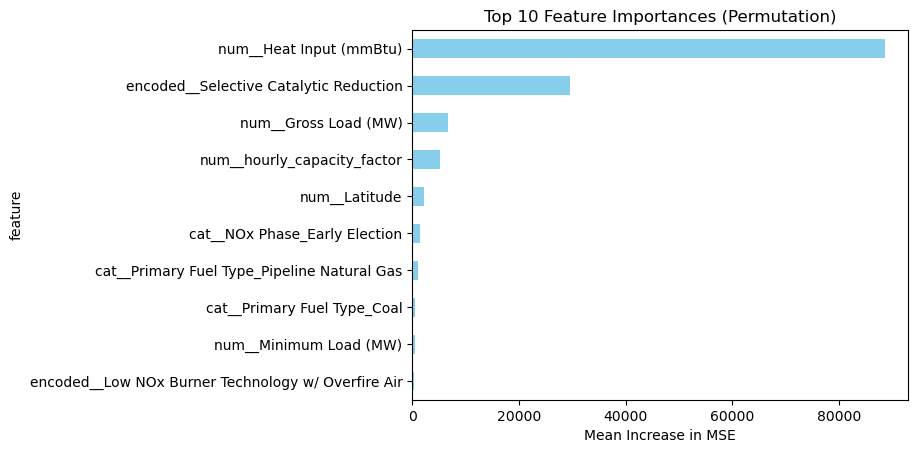

In [97]:
importance_df.head(10).plot.barh(
    x='feature', 
    y='importance_mean', 
    legend=False,
    color='skyblue'
)

plt.xlabel('Mean Increase in MSE')
plt.title('Top 10 Feature Importances (Permutation)')
plt.gca().invert_yaxis()  # get the most important on top
plt.show()


<h3>SHAP</h3>

<h4>XGB</h4>

<h5>SHAP Values</h5>

- global aggregated SHAP values with and without lags
- exploration of SHAP value scatter plots

In [100]:
explainer = shap.TreeExplainer(xgb_default_model_no_lags)

In [ ]:
shap_values = explainer(X_test, approximate=False)

In [ ]:
joblib.dump(shap_values, "WY/Hourly/Concatted File/Modeling/XGB/NOx/Trained Models/shap_values_xgb_default_model_wy_no_lags_with_unmeasured_with_temps.pkl", compress=True)

['WY/Hourly/Concatted File/Modeling/XGB/NOx/Trained Models/shap_values_xgb_default_model_wy_no_lags_no_unmeasured_with_temps.pkl']

In [2]:
shap_values = joblib.load("WY/Hourly/Concatted File/Modeling/XGB/NOx/Trained Models/shap_values_xgb_default_model_wy_no_lags_with_unmeasured_with_temps.pkl")

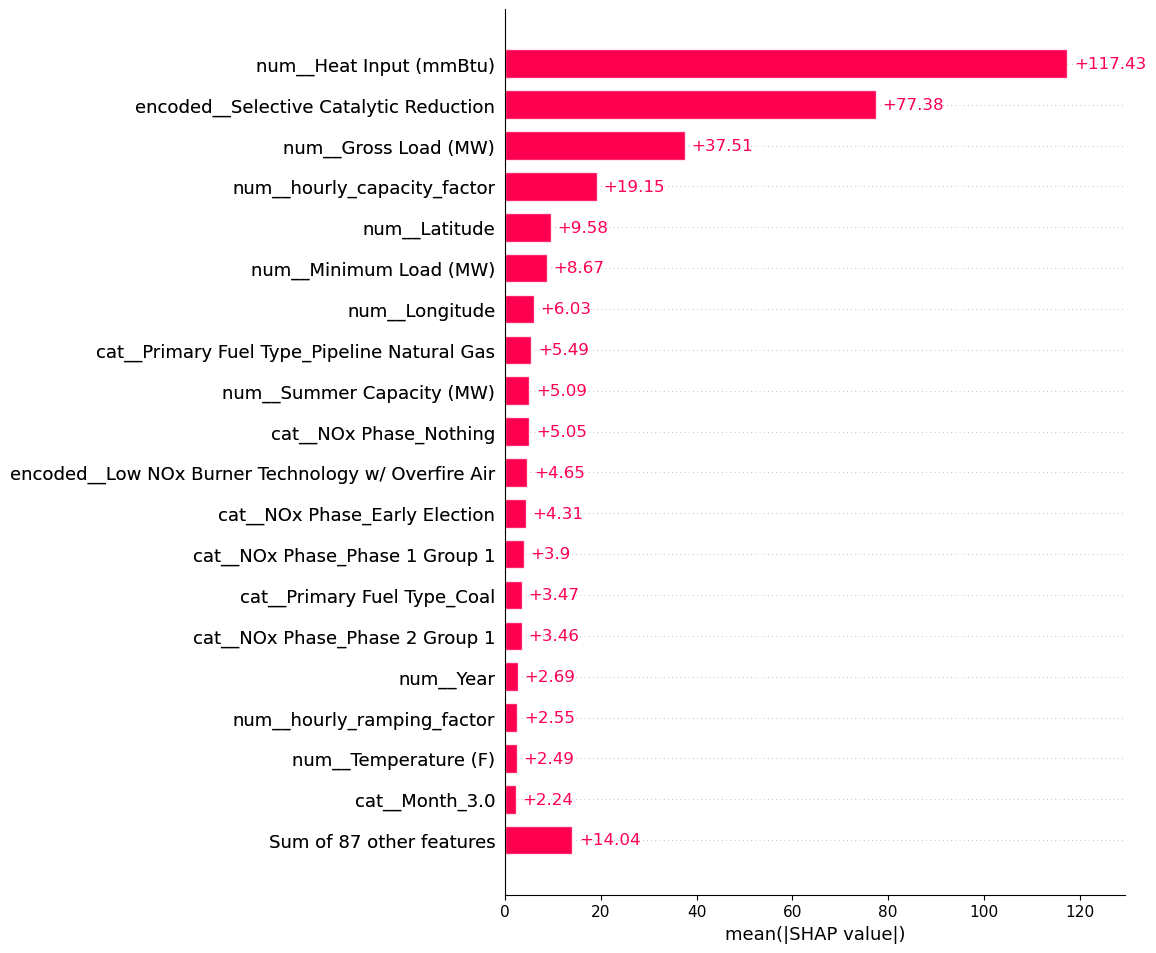

In [ ]:
shap.plots.bar(shap_values, max_display=20)

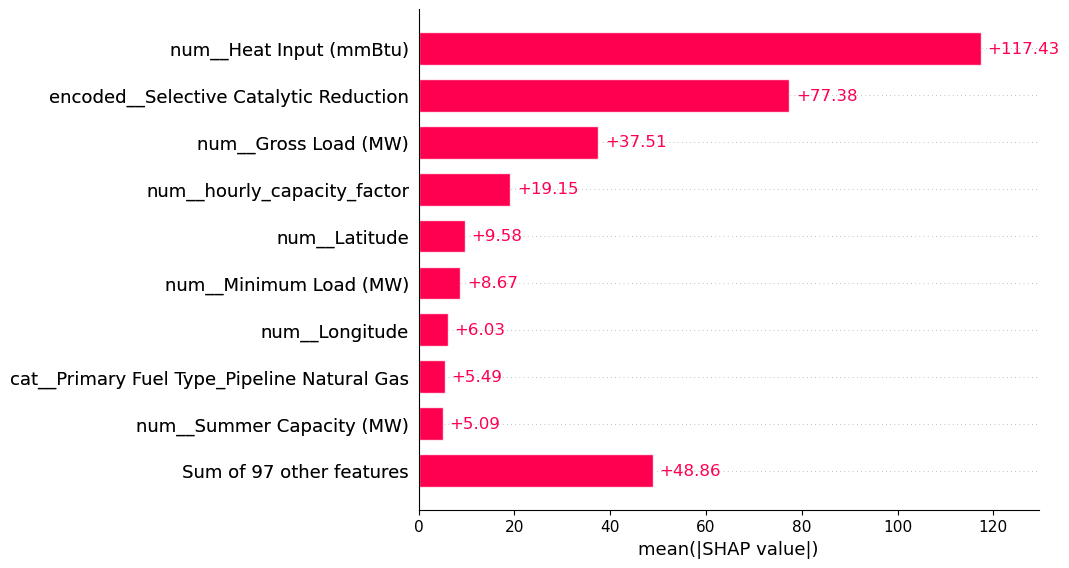

In [3]:
shap.plots.bar(shap_values, max_display=10)

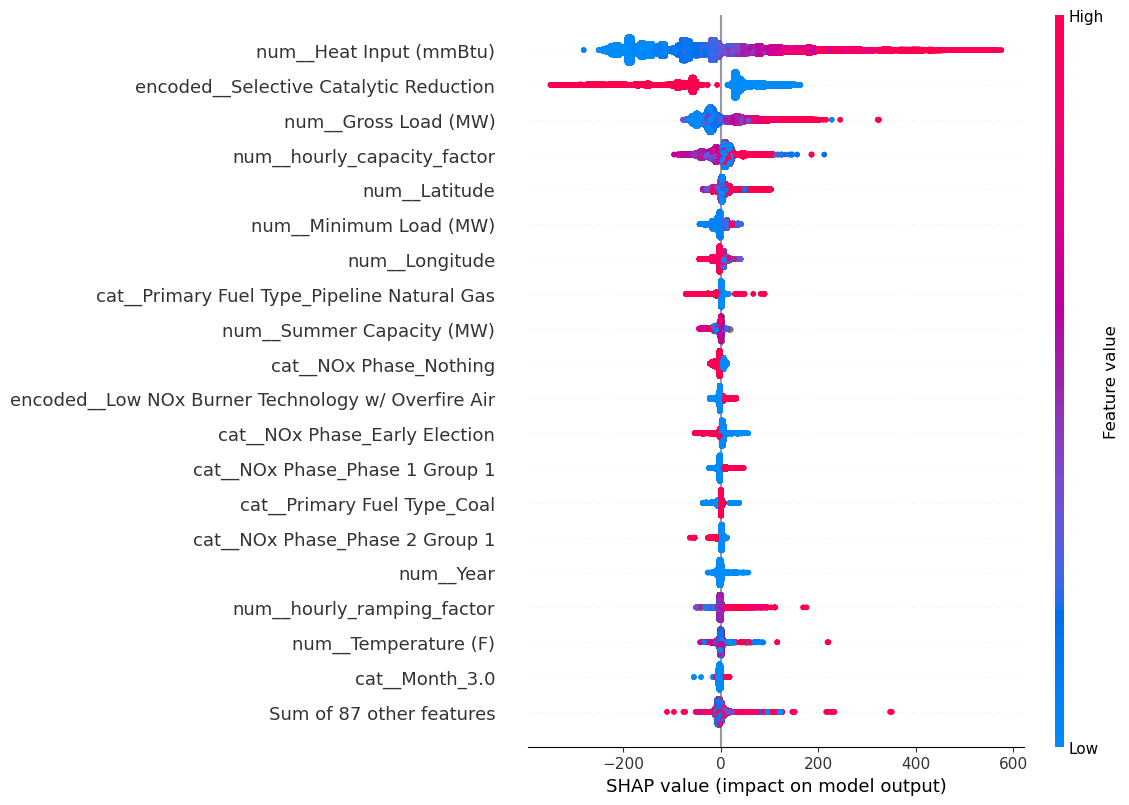

In [ ]:
shap.plots.beeswarm(shap_values, max_display=20)

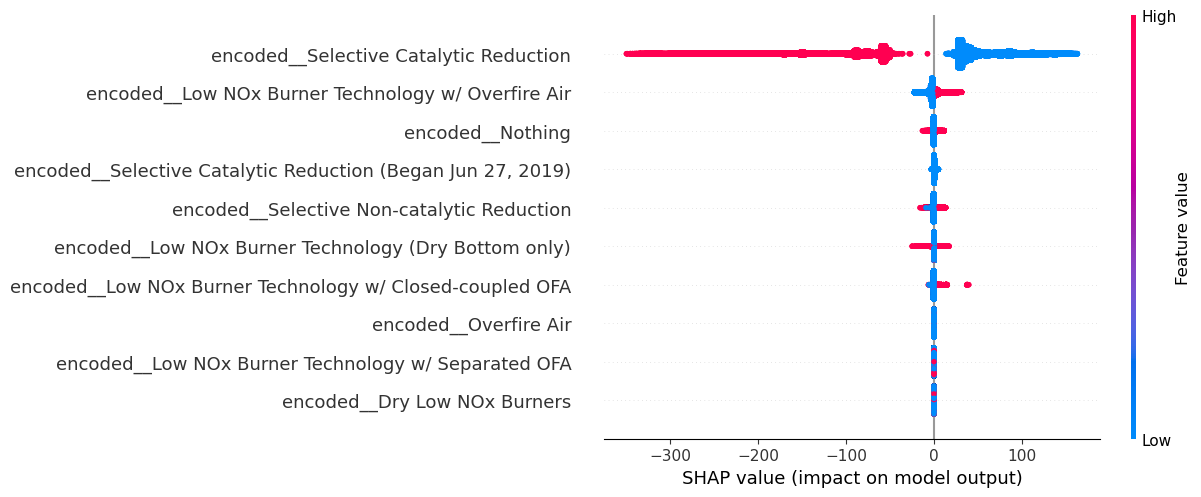

In [4]:
adj_control_cols = []
for control in df_control_cols:
    control = "encoded__" + control
    adj_control_cols.append(control)
    
shap.plots.beeswarm(shap_values[:, adj_control_cols], max_display=20)

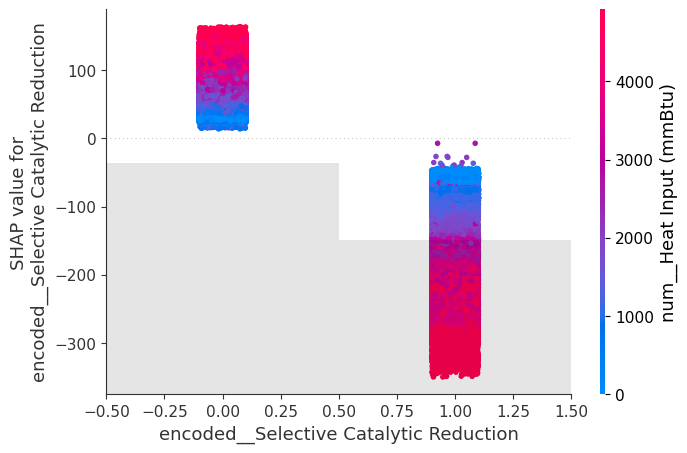

In [117]:
shap.plots.scatter(shap_values[:,"encoded__Selective Catalytic Reduction"], color=shap_values[:,"num__Heat Input (mmBtu)"])

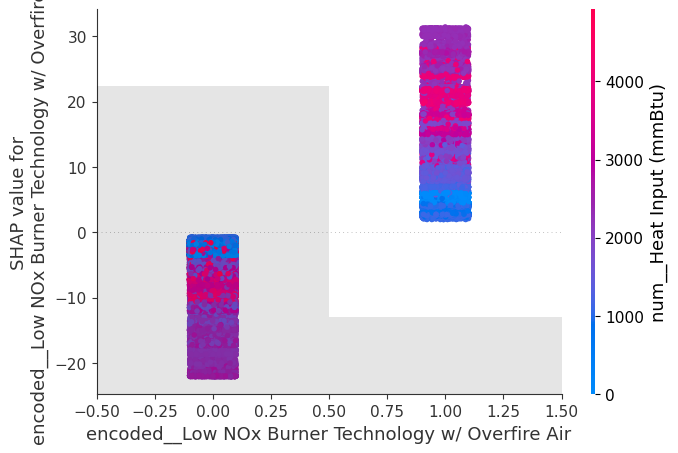

In [ ]:
shap.plots.scatter(shap_values[:,"encoded__Low NOx Burner Technology w/ Overfire Air"], color=shap_values[:,"num__Heat Input (mmBtu)"])

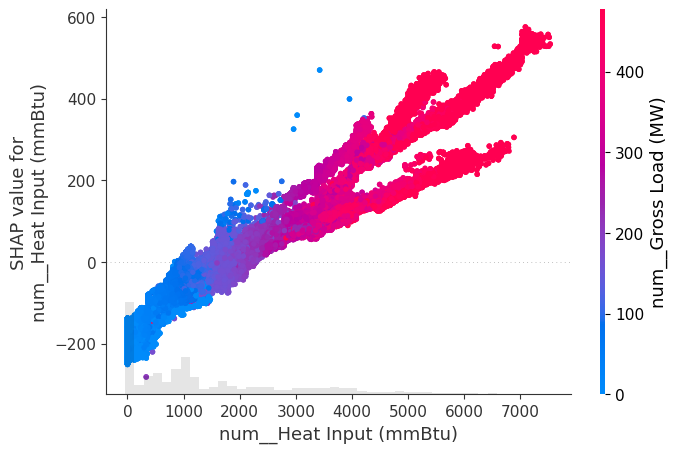

In [128]:
shap.plots.scatter(shap_values[:,"num__Heat Input (mmBtu)"], color=shap_values[:,"num__Gross Load (MW)"])

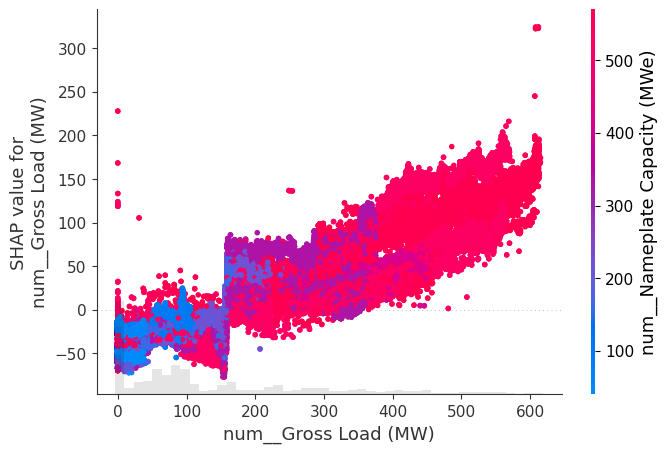

In [129]:
shap.plots.scatter(shap_values[:,"num__Gross Load (MW)"], color=shap_values[:,"num__Nameplate Capacity (MWe)"])

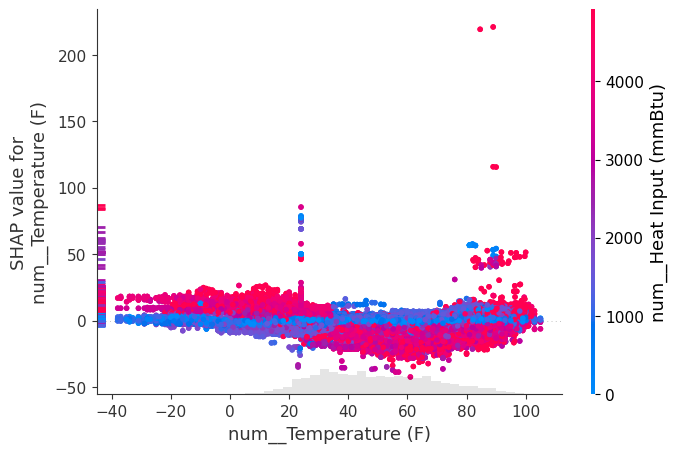

In [ ]:
shap.plots.scatter(shap_values[:,"num__Temperature (F)"], color=shap_values[:,"num__Heat Input (mmBtu)"])

In [150]:
campd_df.groupby(by="Unit Type")["NOx Mass (lbs)"].sum()

Unit Type
Combined cycle                     262,930.84
Combustion turbine                 665,021.12
Dry bottom wall-fired boiler   353,806,176.00
Tangentially-fired             227,806,976.00
Name: NOx Mass (lbs), dtype: float32

In [ ]:
indices_tf = np.where(X_test["cat__Unit Type_Tangentially-fired"] == 1)[0]
indices_dbwfb = np.where(X_test["cat__Unit Type_Dry bottom wall-fired boiler"] == 1)[0]

In [ ]:
shap_values_dbwfb = shap_values[indices_dbwfb, "num__Heat Input (mmBtu)"]
shap_values_tf = shap_values[indices_tf, "num__Heat Input (mmBtu)"]

heat_input_dbwfb = X_test.iloc[indices_dbwfb]["num__Heat Input (mmBtu)"]  
heat_input_tf = X_test.iloc[indices_tf]["num__Heat Input (mmBtu)"]        

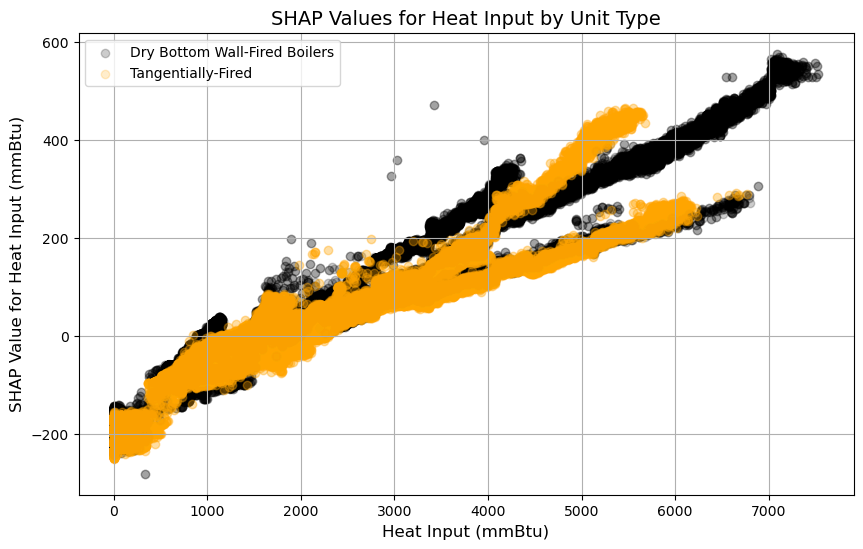

In [ ]:
# Compare Heat Input Behavior across two unit types

plt.figure(figsize=(10, 6))

plt.scatter(
    heat_input_dbwfb,
    shap_values_dbwfb.values,
    alpha=0.2,
    color="black",
    label="Dry Bottom Wall-Fired Boilers"
)

plt.scatter(
    heat_input_tf,
    shap_values_tf.values,
    alpha=0.2,
    color="orange",
    label="Tangentially-Fired"
)

plt.xlabel("Heat Input (mmBtu)", fontsize=12)
plt.ylabel("SHAP Value for Heat Input (mmBtu)", fontsize=12)
plt.title("SHAP Values for Heat Input by Unit Type", fontsize=14)
plt.legend(fontsize=10)
plt.grid(True)

plt.show()

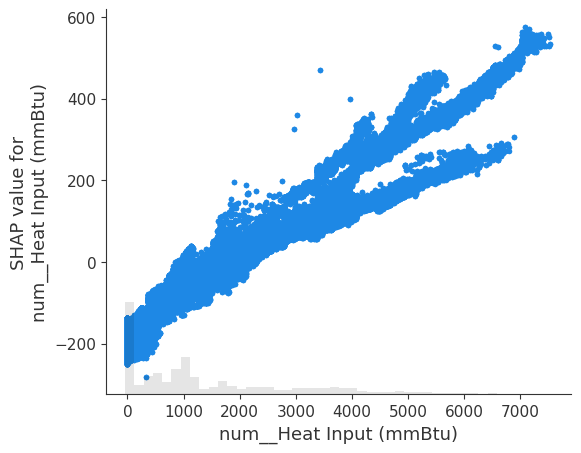

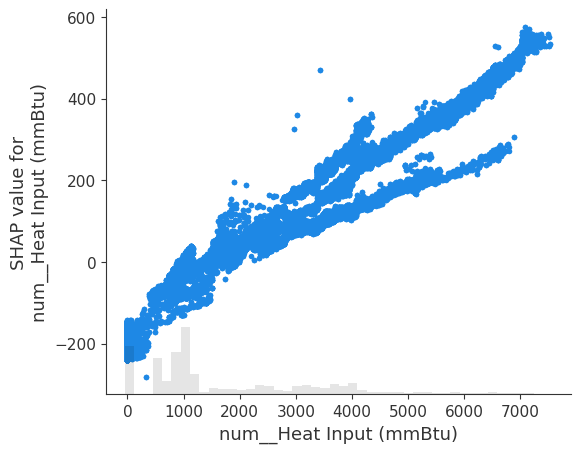

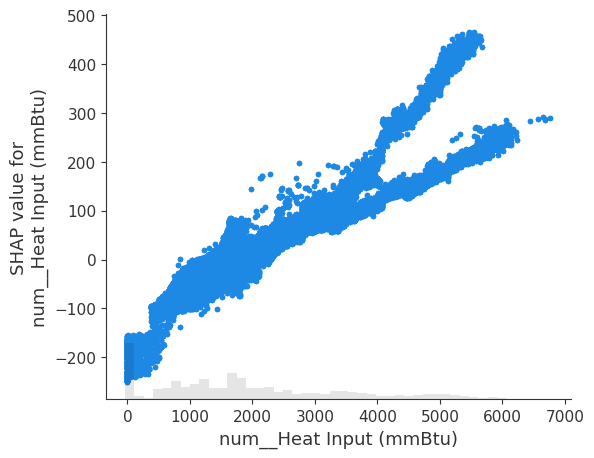

In [ ]:
shap.plots.scatter(shap_values[:,"num__Heat Input (mmBtu)"]) #, color=shap_values[:,"num__Heat Input (mmBtu)"])
shap.plots.scatter(shap_values[indices_dbwfb,"num__Heat Input (mmBtu)"]) #, color=shap_values[:,"num__Heat Input (mmBtu)"])
shap.plots.scatter(shap_values[indices_tf,"num__Heat Input (mmBtu)"]) #, color=shap_values[:,"num__Heat Input (mmBtu)"])